## Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import Libraries


In [2]:
import os
import glob
import random
import copy
import gzip
import argparse
from datetime import datetime
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import wasserstein_distance  # EMD calculation
from scipy.spatial.distance import jensenshannon  # JS calculation
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, Dataset, random_split

import wandb
import time
import psutil

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from sklearn.metrics import silhouette_score, silhouette_samples

torch.backends.cudnn.benchmark = True

## Parameters

In [3]:
# Parameters
FL_ROUNDS: int = 150
LOCAL_EPOCHS: int = 6
NUM_CLIENTS: int = 100
BATCH_SIZE: int = 64
NUM_SELECTED_CLIENTS: int = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLIENTS_DATASETS_PATH = "/content/drive/MyDrive/FYP/Realworld_Distribution_C100_1/"

EXPERIMENT_NAME: str = "CAFA_C100"
MODEL_NAME: str = "VGG19"
DATASET_DISTRIBUTION_TYPE: str = "Realworld_Distribution_C100_1"

HISTORY_SAVE_PATH = '/content/drive/MyDrive/Final_Implementations/RWC100_Impl/history/'
HISTORY_FOLDER_NAME = f'EX-{EXPERIMENT_NAME}_MODEL-{MODEL_NAME}_FLROUND-{FL_ROUNDS}_NUMCLI-{NUM_CLIENTS}_CLILOCALEPOCH-{LOCAL_EPOCHS}_DST{DATASET_DISTRIBUTION_TYPE}'
HISTORY_DIR = os.path.join(HISTORY_SAVE_PATH, HISTORY_FOLDER_NAME)

## Utils

In [4]:
def save_data(split_data, filepath):
    with open(filepath, 'wb') as f:
        pickle.dump(split_data, f)

def load_data(filepath):
    with open(filepath, 'rb') as f:
        return pickle.load(f)

### Load and Save Client Datasets

In [5]:
# Define a filename within the directory for saving/loading the data
DATA_FILENAME = "client_datasets.pkl"
full_data_path = os.path.join(CLIENTS_DATASETS_PATH, DATA_FILENAME)

# Check if the data has already been split and saved
if os.path.exists(full_data_path):
    print(f"Loading previously saved data split from {full_data_path}")
    client_dataset_list = load_data(full_data_path)

Loading previously saved data split from /content/drive/MyDrive/FYP/Realworld_Distribution_C100_1/client_datasets.pkl


In [6]:
client_dataloader_list = [DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True) for client_dataset in client_dataset_list]

### Visualize Client Dataset Distribution

In [7]:
from collections import Counter

def get_label_distribution(trainloader):
    all_labels = []

    for _, labels in trainloader:
        all_labels.extend(labels.tolist())

    label_counts = Counter(all_labels)

    for i in range(10):
        label_counts.setdefault(i, 0)

    return dict(sorted(label_counts.items()))

# Print table header with Total column
header = ["Client"] + list(range(10)) + ["Total"]
col_widths = [8] + [6] * 10 + [8]  # Added extra width for Total column

print("".join(f"{h:>{w}}" for h, w in zip(header, col_widths)))

all_client_total_images = []

# Print each client’s distribution
for i, trainloader in enumerate(client_dataloader_list):
    label_dist = get_label_distribution(trainloader)
    total_images = sum(label_dist.values())
    all_client_total_images.append(total_images)
    row = [i] + [label_dist[k] for k in range(10)] + [total_images]
    print("".join(f"{val:>{w}}" for val, w in zip(row, col_widths)))

print(f"\nClients Total Images: {all_client_total_images}")
print(f"Total Images: {sum(all_client_total_images)}")

  Client     0     1     2     3     4     5     6     7     8     9   Total
       0     0    74     0     0     0    74     0     0    67     0     215
       1    81    74    94     0     0    74     0    87    67    98     575
       2    81    74    94     0   100    74     0    87    67    98     675
       3    82    74     0     0     0    74     0    87    67     0     384
       4    82    74     0     0     0    74     0     0    67     0     297
       5    82    74    94   100     0    74   100    87    67     0     678
       6    82    74    94   100     0    74   100    87    67     0     678
       7     0    74     0     0     0    74     0     0    67     0     215
       8    82    74    94     0     0    74     0    87    67     0     478
       9    82    74     0     0     0    74     0    87    67     0     384
      10     0    74     0     0     0     0     0     0    67     0     141
      11    82    74    94     0   100    74     0    87    67    98     676

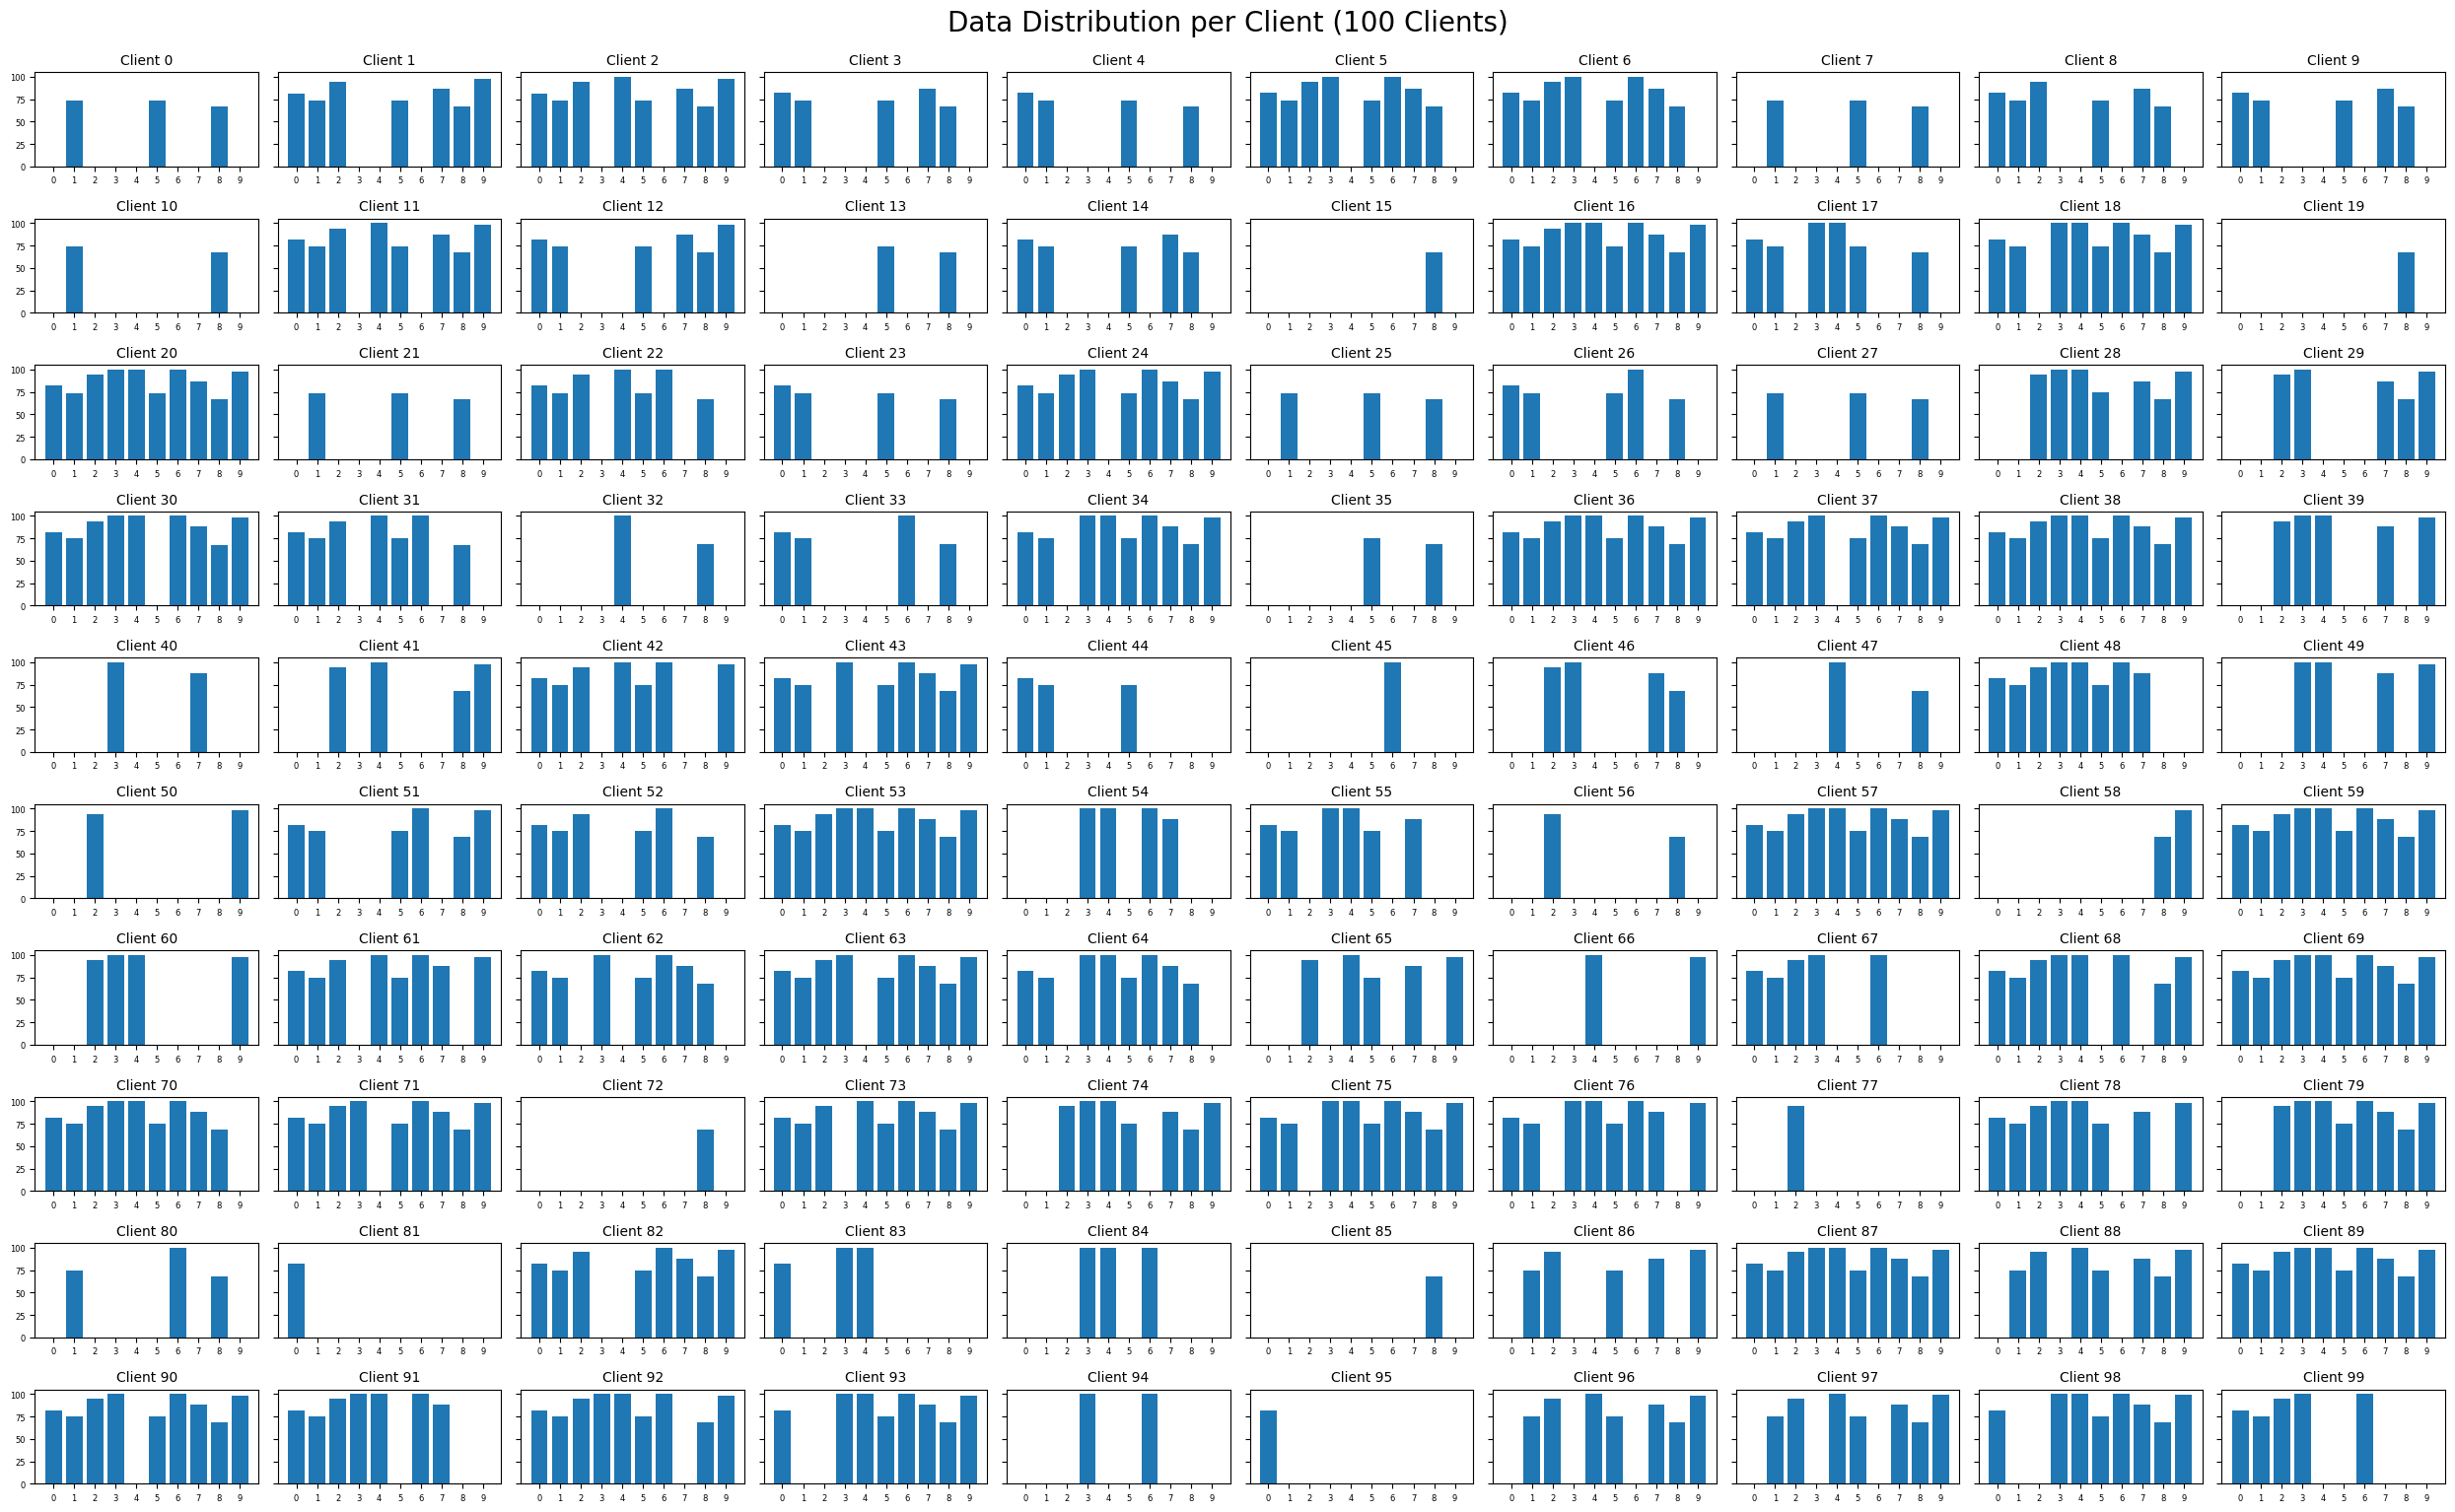

In [8]:
def plot_client_data_distribution_from_loaders(client_dataset_list, num_clients, num_classes=10):
    rows, cols = 10, 10
    fig, axs = plt.subplots(rows, cols, figsize=(25, 15), sharey=True)
    axs = axs.flatten()

    for i in range(num_clients):
        trainloader = client_dataset_list[i]
        label_counts = defaultdict(int)


        for _, labels in trainloader:
            for label in labels:
                label_counts[int(label)] += 1

        labels = list(range(num_classes))
        counts = [label_counts[lbl] for lbl in labels]

        axs[i].bar(labels, counts)
        axs[i].set_title(f'Client {i}', fontsize=10)
        axs[i].set_xticks(range(num_classes))
        axs[i].set_xticklabels(range(num_classes), fontsize=6)
        axs[i].tick_params(axis='y', labelsize=6)

    # Hide any unused subplots if num_clients < rows*cols
    for j in range(num_clients, len(axs)):
        axs[j].axis('off')

    plt.tight_layout()
    plt.suptitle(f"Data Distribution per Client ({NUM_CLIENTS} Clients)", fontsize=20, y=1.02)
    plt.show()

# Plot for 100 clients
plot_client_data_distribution_from_loaders(client_dataloader_list, num_clients=NUM_CLIENTS, num_classes=10)


## Models


### Normal CNN Model

In [9]:
# Define the CNN model
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # [B, 32, 16, 16]
        x = self.pool(F.relu(self.conv2(x)))  # [B, 64, 8, 8]
        x = self.pool(F.relu(self.conv3(x)))  # [B, 128, 4, 4]
        x = x.view(-1, 128 * 4 * 4)           # Flatten
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

### VGG Model

In [10]:
cfg = {
    'VGG11': [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
    'VGG13': [64, 64, 'M', 128, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
    'VGG16': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M'],
    'VGG19': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 256, 'M', 512, 512, 512, 512, 'M', 512, 512, 512, 512, 'M'],
}

class VGG(nn.Module):
    def __init__(self, vgg_name):
        super(VGG, self).__init__()
        self.features = self._make_layers(cfg[vgg_name])
        self.classifier = nn.Sequential(
            nn.Linear(512, 512),
            nn.ReLU(True),
            nn.Linear(512, 512),
            nn.ReLU(True),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        out = self.features(x)
        out = out.view(out.size(0), -1)
        out = self.classifier(out)
        output = F.log_softmax(out, dim=1)
        return output

    def _make_layers(self, cfg):
        layers = []
        in_channels = 3
        for x in cfg:
            if x == 'M':
                layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
            else:
                layers += [nn.Conv2d(in_channels, x, kernel_size=3, padding=1),
                           nn.BatchNorm2d(x),
                           nn.ReLU(inplace=True)]
                in_channels = x
        layers += [nn.AvgPool2d(kernel_size=1, stride=1)]
        return nn.Sequential(*layers)

## Client


In [11]:
class Client:

    def __init__(self, id):
        self.id = id
        full_dataset = client_dataset_list[id]   # this is now a raw dataset (list of (image, label))

        # Convert list into a TensorDataset-like object
        # You can keep it as list, but wrapping in Dataset is safer for DataLoader
        class ListDataset(Dataset):
            def __init__(self, data):
                self.data = data
            def __len__(self):
                return len(self.data)
            def __getitem__(self, idx):
                return self.data[idx]

        full_dataset = ListDataset(full_dataset)

        # Split 80% train, 20% val
        train_size = int(0.8 * len(full_dataset))
        val_size = len(full_dataset) - train_size
        train_subset, val_subset = random_split(full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(int(self.id)))

        # Create loaders
        self.trainloader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
        self.valloader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
        self.full_dataloader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True)

        # Save dataset sizes
        self.dataset_size = len(train_subset)
        self.val_size = len(val_subset)


    def calculate_label_distribution(self):
        all_labels = []
        for _, labels in self.trainloader:
            all_labels.extend(labels.tolist())

        for _, labels in self.valloader:
            all_labels.extend(labels.tolist())

        label_counts = Counter(all_labels)
        for i in range(10):
            label_counts.setdefault(i, 0)
        sorted_distribution = dict(sorted(label_counts.items()))
        return sorted_distribution

    def calculate_label_probability_distribution(self):
      sorted_distribution = self.calculate_label_distribution()
      counts = np.array(list(sorted_distribution.values()))
      total = counts.sum()
      if total > 0:
          probs = counts / total
      else:
          probs = counts
      return probs

    def calculate_emd(self):
        reference_dist = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
        client_dist = self.calculate_label_distribution()
        client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
        reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

        client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
        reference_probs = reference_counts / reference_counts.sum()

        labels = np.arange(10)
        emd = wasserstein_distance(labels, labels, u_weights=client_probs, v_weights=reference_probs)
        return emd

    def calculate_js_divergence(self):
        reference_dist = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
        client_dist = self.calculate_label_distribution()
        client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
        reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

        client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
        reference_probs = reference_counts / reference_counts.sum()

        return jensenshannon(client_probs, reference_probs, base=2.0)

    def calculate_js_divergence_manualy(self):
        reference_dist = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
        client_dist = self.calculate_label_distribution()
        client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
        reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

        # Normalize to probabilities
        client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
        reference_probs = reference_counts / reference_counts.sum()

        # Mixture distribution
        m = 0.5 * (client_probs + reference_probs)

        # Small epsilon to avoid log(0)
        eps = 1e-12
        client_probs = np.clip(client_probs, eps, 1)
        reference_probs = np.clip(reference_probs, eps, 1)
        m = np.clip(m, eps, 1)

        # KL divergence function
        def kl_divergence(p, q):
            return np.sum(p * np.log2(p / q))

        # Jensen-Shannon divergence (always between 0 and 1)
        js_div = 0.5 * kl_divergence(client_probs, m) + 0.5 * kl_divergence(reference_probs, m)

        return js_div

    def calculate_shannon_entropy(self, distribution):
        """
        Simplified Shannon entropy calculation.
        """
        return -np.sum(distribution * np.log2(distribution))

    def calculate_weight_metric(self):

        dataset = self.full_dataloader

        if len(dataset) == 0:
            return 0.0

        # Collect labels
        labels = []
        for _, lbls in dataset:
            if isinstance(lbls, torch.Tensor):
                labels.extend(lbls.tolist())
            else:
                labels.extend(lbls)

        if len(labels) == 0:
            return 0.0

        # Calculate distribution from ONLY the labels present
        counter = Counter(labels)
        total = len(labels)
        distribution_array = np.array([count / total for count in counter.values()])

        # Now distribution_array contains only non-zero probabilities
        shannon_entropy = self.calculate_shannon_entropy(distribution_array)

        print(shannon_entropy)

        if shannon_entropy <= 0.0:
            weight_metric = (0.5**2)*np.log2(self.dataset_size)
        else:
            weight_metric = (shannon_entropy**2)*(np.log2(self.dataset_size))

        return weight_metric

    def get_combined_agg_weight_js_client_size(self, reference_dist):
        js_value = self.calculate_js_divergence_manualy()
        dataset_size = self.dataset_size
        inverted_js = 1 - js_value
        return inverted_js * dataset_size

    def get_client_dataset_size(self):
        return self.dataset_size

    def train_local_with_full_dataset(self, global_model, epochs, device):
        model = copy.deepcopy(global_model).to(device)
        model.train()
        optimizer = optim.SGD(model.parameters(), lr=1e-1)
        criterion =  F.nll_loss # option 2 : criterion = nn.CrossEntropyLoss()

        val_accuracys = []
        val_losses = []

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            prev_model = copy.deepcopy(model)

            for inputs, labels in self.full_dataloader:
              inputs, labels = inputs.to(device), labels.to(device)

              optimizer.zero_grad()
              outputs = model(inputs)
              loss = criterion(outputs, labels)
              loss.backward()
              optimizer.step()

              total_loss += loss.item() * inputs.size(0)
              _, predicted = outputs.max(1)
              correct += predicted.eq(labels).sum().item()
              total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}")

            if accuracy == 100.00:
              print(f"Training accuracy is 100 at {epoch+1}")
              break

        return model.state_dict()

    def train_local_with_trainloader(self, global_model, epochs, device):
        model = copy.deepcopy(global_model).to(device)
        model.train()
        optimizer = optim.SGD(model.parameters(), lr=1e-1)
        criterion =  F.nll_loss # option 2 : criterion = nn.CrossEntropyLoss()

        val_accuracys = []
        val_losses = []

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            prev_model = copy.deepcopy(model)

            for inputs, labels in self.trainloader:
              inputs, labels = inputs.to(device), labels.to(device)

              optimizer.zero_grad()
              outputs = model(inputs)
              loss = criterion(outputs, labels)
              loss.backward()
              optimizer.step()

              total_loss += loss.item() * inputs.size(0)
              _, predicted = outputs.max(1)
              correct += predicted.eq(labels).sum().item()
              total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}")

            if accuracy == 100.00:
              print(f"Training accuracy is 100 at {epoch+1}")
              break

        return model.state_dict()

    def train_local_fedprox(self, global_model, epochs, device, mu=0.01):
        model = copy.deepcopy(global_model).to(device)
        model.train()
        optimizer = optim.SGD(model.parameters(), lr=1e-1)
        criterion =  F.nll_loss # option 2 : criterion = nn.CrossEntropyLoss()

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            for dataloader in self.trainloader:
                for inputs, labels in dataloader:

                  inputs, labels = inputs.to(device), labels.to(device)

                  optimizer.zero_grad()
                  outputs = model(inputs)
                  loss = criterion(outputs, labels)

                  # ➕ Add FedProx proximal term
                  prox_term = 0.0
                  for w, w_t in zip(model.parameters(), global_model.parameters()):
                      prox_term += ((w - w_t) ** 2).sum()
                  loss += (mu / 2) * prox_term

                  loss.backward()
                  optimizer.step()

                  total_loss += loss.item() * inputs.size(0)
                  _, predicted = outputs.max(1)
                  correct += predicted.eq(labels).sum().item()
                  total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}%")

        return model.state_dict()


    # Test Client Model
    def test_client_model(self, model, testloader, device):
        model.eval()
        correct, total = 0, 0
        total_loss = 0.0
        criterion = F.nll_loss

        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total
        return accuracy, avg_loss

    def calculate_weighted_val_accuracy(self, client_model, device):
        client_model.eval()
        correct, total = 0, 0
        total_loss = 0.0
        criterion = F.nll_loss

        with torch.no_grad():
            for images, labels in self.valloader:
                images, labels = images.to(device), labels.to(device)
                outputs = client_model(images)
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total
        weighted_accuracy = accuracy * self.val_size
        return weighted_accuracy, accuracy, avg_loss

## Server


In [33]:
class Server:

    def __init__(self, model):
        self.model = model

    # FedAvg Algorithm
    def fed_avg(self, client_models_param_list):
        avg_params = copy.deepcopy(client_models_param_list[0])
        for key in avg_params:
            for i in range(1, len(client_models_param_list)):
                avg_params[key] += client_models_param_list[i][key]
            # Explicitly cast to float before division and back to original type
            avg_params[key] = (avg_params[key].float() / len(client_models_param_list)).to(avg_params[key].dtype)
        return avg_params

    # Weighted FedAvg
    def weighted_fed_avg(self, models_params, weights):
        avg_params = copy.deepcopy(models_params[0])
        total_weight = sum(weights)
        for param_key in avg_params:
            weighted_sum = torch.zeros_like(avg_params[param_key], dtype=torch.float) # Use float for summation
            for i in range(len(models_params)):
                client_param = models_params[i][param_key].float() # Cast client params to float
                weighted_sum += client_param * weights[i]
            # Cast back to original type after division
            avg_params[param_key] = (weighted_sum / total_weight).to(avg_params[param_key].dtype)
        return avg_params

    # Weighted FedAvg
    def client_selection_fed_avg(self, models_params, weights):
        print(f"\nAggregate using Client Selection.")
        avg_params = copy.deepcopy(models_params[0])

        selected_clients = 0
        for weight in weights:
          if weight > 0.8:
            selected_clients += 1

        for param_key in avg_params:
            weighted_sum = torch.zeros_like(avg_params[param_key])
            for i in range(1, len(models_params)):
                client_param = models_params[i][param_key]
                if weights[i] > 0.8:
                  weighted_sum += client_param
            print(f"Selected Clients: {selected_clients}")
            avg_params[param_key] = weighted_sum / selected_clients
        return avg_params


    # Assign Weight For Clients based on IID nature mesures (EMD/JS/..)
    def iid_mesure_to_weights(self, client_iid_mesure_list):
        d_min, d_max = min(client_iid_mesure_list), max(client_iid_mesure_list)
        if d_max == d_min:
            return [1.0 for _ in client_iid_mesure_list]  # Avoid div by zero
        return [(1 - (value - d_min) / (d_max - d_min)) for value in client_iid_mesure_list]

    # Aggregation
    def aggregate_models(self, client_models, weights=None):
        if weights is None:
            print(f"\nAggregate using FedAvg.")
            aggregated_model_params = self.fed_avg(client_models)
        else:
            print(f"\nAggregate using Weighted FedAvg.")
            aggregated_model_params = self.weighted_fed_avg(client_models, weights)
        self.model.load_state_dict(aggregated_model_params)
        return self.model

    # Test Global Model
    def test_model(self, testloader, device):
        self.model.eval()
        correct, total = 0, 0
        total_loss = 0.0
        criterion = F.nll_loss

        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = self.model(images)  # FIXED: self.model
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total
        return accuracy, avg_loss

    # evaluate silhouette scores for different k
    def evaluate_kmeans_silhouette(self, distribution_matrix, k_range):
        silhouette_scores = []
        for k in k_range:
            kmeans = KMeans(n_clusters=k, random_state=0)
            labels = kmeans.fit_predict(distribution_matrix)
            score = silhouette_score(distribution_matrix, labels)
            silhouette_scores.append(score)
            print(f"k={k}, silhouette score={score:.4f}")
        return silhouette_scores

    def find_optimal_k_and_client_clusters(self, num_clients, distribution_matrix):

        unique_count = np.unique(distribution_matrix, axis=0).shape[0]
        k_range = range(2, min(num_clients, unique_count) + 1)

        silhouette_scores = evaluate_kmeans_silhouette(distribution_matrix, k_range)

        # Plot silhouette scores vs k
        plt.figure(figsize=(8, 5))
        plt.plot(k_range, silhouette_scores, marker='o')
        plt.title("Silhouette Score vs Number of Clusters (k)")
        plt.xlabel("Number of clusters (k)")
        plt.ylabel("Silhouette Score")
        plt.xticks(k_range)
        ax = plt.gca()
        ax.set_xticklabels(k_range, fontsize=10)
        plt.grid(True)
        plt.show()

        # Best k
        best_k = k_range[np.argmax(silhouette_scores)]
        print(f"\n✅ Optimal k = {best_k}, Silhouette Score = {max(silhouette_scores):.4f}")

        kmeans = KMeans(n_clusters=best_k, random_state=0)
        client_cluster_labels = kmeans.fit_predict(distribution_matrix)

        return best_k, silhouette_scores, client_cluster_labels

## Federated Learning Training


In [13]:
def save_history_every_n_rounds(
    fl_round,
    model,
    accuracy_list,
    loss_list,
    fl_train_time_list,
    client_train_time_list,
    agg_time_list,
    system_usage_list,
    history_save_path,
    history_folder_name,
    n=10
):
    """
    Saves training history (accuracy, loss, times) and model checkpoints
    every n rounds, and at the last round.
    """

    # Build file paths
    base_folder = os.path.join(history_save_path, history_folder_name)
    history_file = os.path.join(base_folder, "history.pkl")
    model_path = os.path.join(base_folder, "model", "model.pth")

    # Ensure folders exist
    os.makedirs(base_folder, exist_ok=True)
    os.makedirs(os.path.join(base_folder, "model"), exist_ok=True)

    # Save every n rounds, or at the very last round
    if (fl_round + 1) % n == 0 or (fl_round + 1) == FL_ROUNDS:

        # Collect everything in one dictionary
        history = {
            "fl_rounds": list(range(fl_round + 1)),
            "accuracy": accuracy_list,
            "loss": loss_list,
            "fl_round_time": fl_train_time_list,
            "client_train_time": client_train_time_list,
            "agg_time": agg_time_list,
            "system_usage": system_usage_list
        }

        # Save history in one file
        with open(history_file, "wb") as f:
            pickle.dump(history, f)

        # Save model checkpoint
        torch.save(model.state_dict(), model_path)

        print(f"[Round {fl_round+1}] ✅ Saved all history + model checkpoint in one file.")

In [ ]:
#cca506f824e9db910b7b4a407afc0b36ba655c28

In [14]:
wandb.login(key="cca506f824e9db910b7b4a407afc0b36ba655c28")
wandb.init(
    project="RealWorldDistribution_C100_1",  # change to your project name
    config={
        "model": MODEL_NAME,
        "fl_rounds": FL_ROUNDS,
        "clients": NUM_CLIENTS,
        "selected_clients": NUM_SELECTED_CLIENTS,
        "local_epochs": LOCAL_EPOCHS,
        "dataset_distribution": DATASET_DISTRIBUTION_TYPE,
        "device": str(DEVICE),
    },
    name="CAFA_C100"
)

def get_system_usage(device):
    usage = {
        "cpu_percent": psutil.cpu_percent(),
        "ram_percent": psutil.virtual_memory().percent,
    }
    if "cuda" in str(device):
        usage.update({
            "gpu_percent": torch.cuda.utilization(0),  # if you have pynvml installed
            "gpu_mem_allocated": torch.cuda.memory_allocated(0) / 1e6, # MB
            "gpu_mem_reserved": torch.cuda.memory_reserved(0) / 1e6,
        })
    return usage


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: sjanugopanstudy (sjanugopanstudy-jaanu) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


### Global Test Dataset

In [15]:
global_testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))]))
global_testset_loader = DataLoader(global_testset, batch_size=100, )

100%|██████████| 170M/170M [00:13<00:00, 13.0MB/s]


### Training

In [16]:
def get_last_checkpoint(history_dir):
    """Return the last saved FL round number from history, or None if not found."""
    history_file = os.path.join(history_dir, "history.pkl")

    if not os.path.exists(history_file):
        return None

    with open(history_file, 'rb') as f:
        history = pickle.load(f)

    if not history:
        return None

    return history['fl_rounds']

def load_checkpoint(history_dir, model):
    """Load model state and history for a given round."""

    # Load model
    model_path = os.path.join(history_dir, "model", "model.pth")
    model.load_state_dict(torch.load(model_path))

    # Load history
    history_path = os.path.join(history_dir, f"history.pkl")
    with open(history_path, "rb") as f:
        history = pickle.load(f)

    return history

### Clustering

k=2, silhouette score=0.3023
k=3, silhouette score=0.3269
k=4, silhouette score=0.3543
k=5, silhouette score=0.3688
k=6, silhouette score=0.3807
k=7, silhouette score=0.3103
k=8, silhouette score=0.3045
k=9, silhouette score=0.3356
k=10, silhouette score=0.3421
k=11, silhouette score=0.3584
k=12, silhouette score=0.3563
k=13, silhouette score=0.3811
k=14, silhouette score=0.3882
k=15, silhouette score=0.3181
k=16, silhouette score=0.3474
k=17, silhouette score=0.3596
k=18, silhouette score=0.3626
k=19, silhouette score=0.3650
k=20, silhouette score=0.3668
k=21, silhouette score=0.3341
k=22, silhouette score=0.3449
k=23, silhouette score=0.3558
k=24, silhouette score=0.3608
k=25, silhouette score=0.3640
k=26, silhouette score=0.3611
k=27, silhouette score=0.3801
k=28, silhouette score=0.3914
k=29, silhouette score=0.3798
k=30, silhouette score=0.3827
k=31, silhouette score=0.3812
k=32, silhouette score=0.3789
k=33, silhouette score=0.3774
k=34, silhouette score=0.3711
k=35, silhouette s

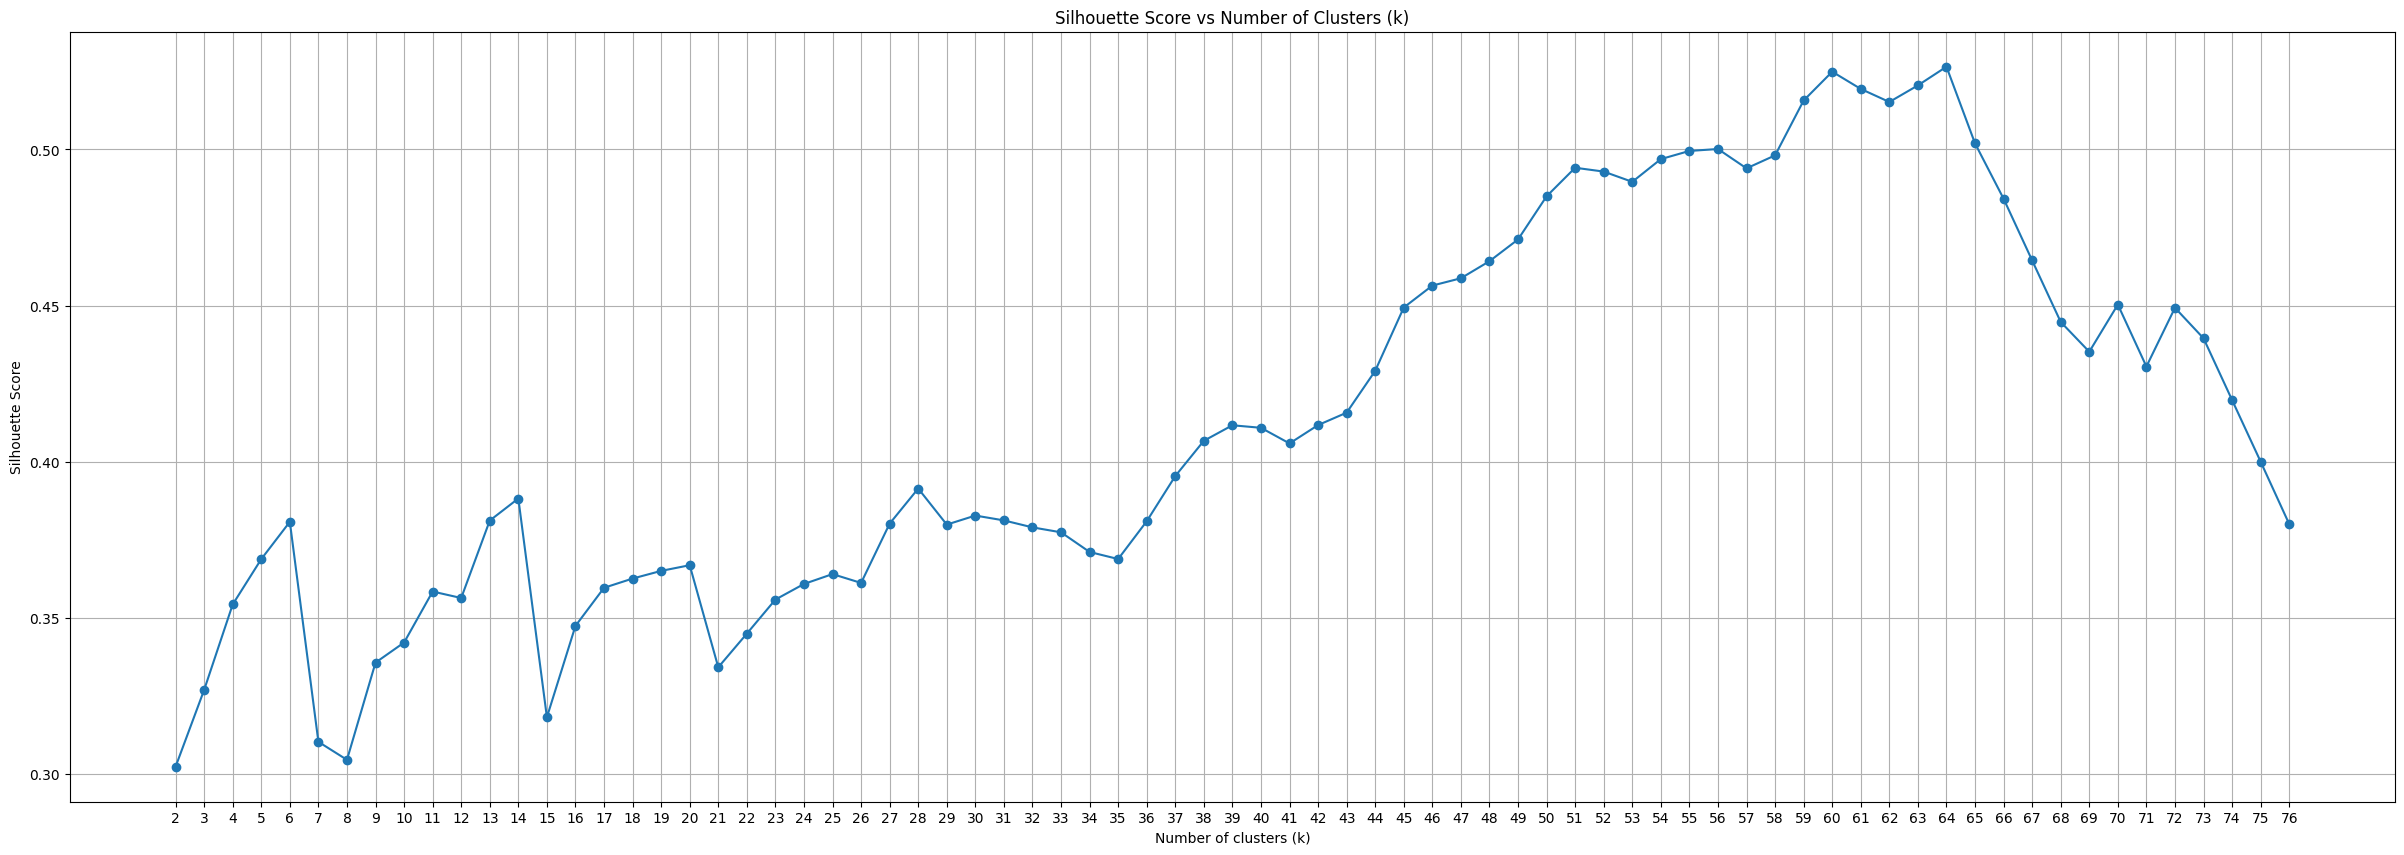


✅ Optimal k = 64, Silhouette Score = 0.5265


In [32]:
# --- Step 1: calculate label distribution for each client ---
def calculate_label_probability_distribution(client_dataloader):
    all_labels = []
    for _, labels in client_dataloader:
        all_labels.extend(labels.tolist())

    label_counts = Counter(all_labels)
    for i in range(10):  # CIFAR-10 has 10 classes
        label_counts.setdefault(i, 0)

    sorted_distribution = dict(sorted(label_counts.items()))
    counts = np.array(list(sorted_distribution.values()))

    # Convert counts to probabilities (normalize)
    total = counts.sum()
    if total > 0:
        probs = counts / total
    else:
        probs = counts  # all zeros case (empty client dataset)

    return probs

# --- Step 2: convert all client dataloaders to distribution matrix ---
def build_distribution_matrix(client_dataset_list):
    distributions = []
    for client_loader in client_dataset_list:
        dist = calculate_label_probability_distribution(client_loader)
        distributions.append(dist)
    return np.array(distributions)

# --- Step 3: evaluate silhouette scores for different k ---
def evaluate_kmeans_silhouette(distribution_matrix, k_range):
    silhouette_scores = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=0)
        labels = kmeans.fit_predict(distribution_matrix)
        score = silhouette_score(distribution_matrix, labels)
        silhouette_scores.append(score)
        print(f"k={k}, silhouette score={score:.4f}")
    return silhouette_scores

# --- Step 4: wrapper function to run the analysis ---
def find_optimal_k(client_dataset_list, num_clients):
    distribution_matrix = build_distribution_matrix(client_dataset_list)

    unique_count = np.unique(distribution_matrix, axis=0).shape[0]
    k_range = range(2, min(len(client_dataloader_list), unique_count) + 1)

    scores = evaluate_kmeans_silhouette(distribution_matrix, k_range)

    # Plot silhouette scores vs k
    plt.figure(figsize=(30, 10))
    plt.plot(k_range, scores, marker='o')
    plt.title("Silhouette Score vs Number of Clusters (k)")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Silhouette Score")
    plt.xticks(k_range)
    ax = plt.gca()
    ax.set_xticklabels(k_range, fontsize=10)
    plt.grid(True)
    plt.show()

    # Best k
    best_k = k_range[np.argmax(scores)]
    print(f"\n✅ Optimal k = {best_k}, Silhouette Score = {max(scores):.4f}")
    return best_k, scores




best_k, scores = find_optimal_k(client_dataloader_list, num_clients=len(client_dataloader_list))


In [34]:
#k_value = best_k
k_value = 64
distribution_matrix = build_distribution_matrix(client_dataloader_list)
kmeans = KMeans(n_clusters=k_value, random_state=0)
client_cluster_labels = kmeans.fit_predict(distribution_matrix)

print(f"Client Cluster Labels for Optimal K-{k_value}: {client_cluster_labels}")

Client Cluster Labels for Optimal K-64: [ 3 28 48 11 18 39 39  3 44 11 22 48 50 13 11  2  1 25 34  2  1  3 29 18
 30  3  9  3  8 36 63 29 10 38 34 13  1 30  1 31 16 32 55 59 27  6 20 10
 61 42  5 41 46  1  0 33 12  1  7  1 45 40 51 30 57 43 15 21 49  1 23 30
  2 60  8 34 62 14 47 53 26  4 54 24 37  2 35  1 17  1 30 52 56 58 19  4
 17 17 58 21]


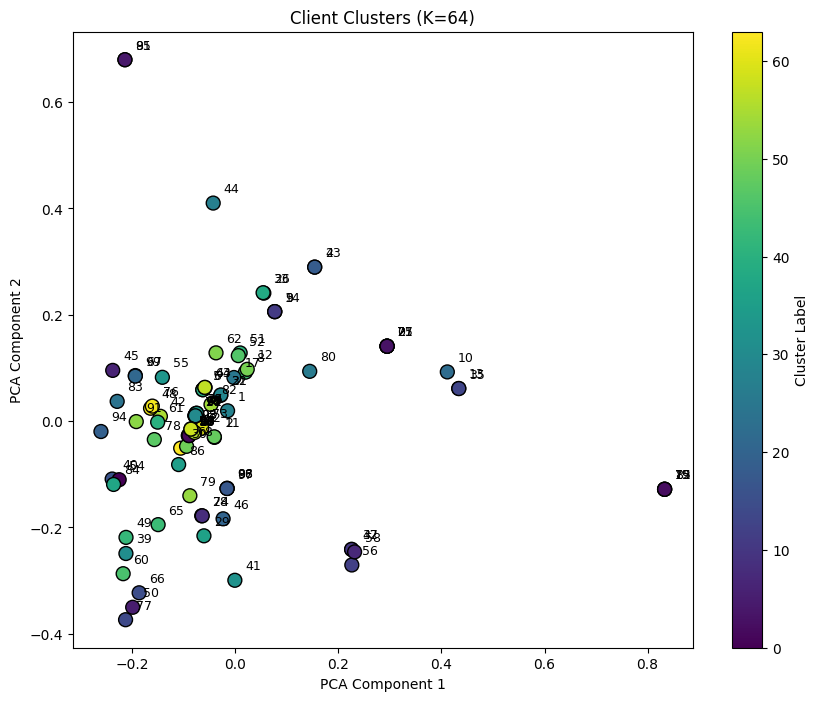

In [35]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# Reduce distribution_matrix to 2D for plotting
pca = PCA(n_components=2)
reduced_matrix = pca.fit_transform(distribution_matrix)

# Plot
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    reduced_matrix[:, 0],
    reduced_matrix[:, 1],
    c=client_cluster_labels,
    cmap='viridis',
    s=100,
    edgecolors='k'
)

# Annotate points with client index
for i, (x, y) in enumerate(reduced_matrix):
    plt.text(x+0.02, y+0.02, str(i), fontsize=9)

plt.title(f"Client Clusters (K={k_value})")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster Label")
plt.show()


In [20]:
reference_distribution = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}

k=2, silhouette score=0.3023
k=3, silhouette score=0.3269
k=4, silhouette score=0.3543
k=5, silhouette score=0.3688
k=6, silhouette score=0.3807
k=7, silhouette score=0.3103
k=8, silhouette score=0.3045
k=9, silhouette score=0.3356
k=10, silhouette score=0.3421
k=11, silhouette score=0.3584
k=12, silhouette score=0.3563
k=13, silhouette score=0.3811
k=14, silhouette score=0.3882
k=15, silhouette score=0.3181
k=16, silhouette score=0.3474
k=17, silhouette score=0.3596
k=18, silhouette score=0.3626
k=19, silhouette score=0.3650
k=20, silhouette score=0.3668
k=21, silhouette score=0.3341
k=22, silhouette score=0.3449
k=23, silhouette score=0.3558
k=24, silhouette score=0.3608
k=25, silhouette score=0.3640
k=26, silhouette score=0.3611
k=27, silhouette score=0.3801
k=28, silhouette score=0.3914
k=29, silhouette score=0.3798
k=30, silhouette score=0.3827
k=31, silhouette score=0.3812
k=32, silhouette score=0.3789
k=33, silhouette score=0.3774
k=34, silhouette score=0.3711
k=35, silhouette s

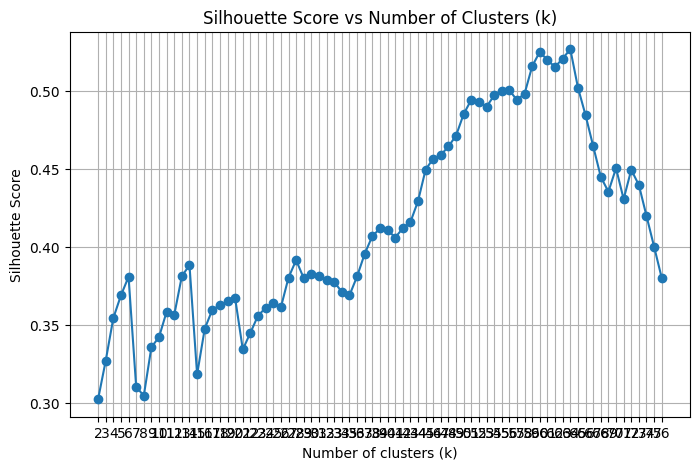

Streaming output truncated to the last 5000 lines.
Combain Aggregation Weights: [66.3, 69.3, 804.0, 22.2, 130.2, 39.4, 30.3, 195.0, 94.60000000000001, 784.0]

Aggregate using Weighted FedAvg.

Federated Learning Round 95 Global Model => Accuracy: 75.21%, Loss: 0.9396
[Round 95] ✅ Saved all history + model checkpoint in one file.

--- Federated Learning Round 96 ---
----------------------------------------------------
Selected Clients: [72 51 98 61  3 18 57 34 50 39]

 No-0: Client 72: Local Training
----------------------------------------------------
Client 72 Epoch 1: Loss = 2.8846, Accuracy = 38.89
Client 72 Epoch 2: Loss = 0.1251, Accuracy = 96.30
Client 72 Epoch 3: Loss = 0.0138, Accuracy = 100.00
Training accuracy is 100 at 3

 No-1: Client 51: Local Training
----------------------------------------------------
Client 51 Epoch 1: Loss = 0.4449, Accuracy = 86.93
Client 51 Epoch 2: Loss = 0.2874, Accuracy = 90.95
Client 51 Epoch 3: Loss = 0.1631, Accuracy = 96.48
Client 51 Epoch 4:

In [36]:
# Initialize global model
global_model = VGG('VGG19').to(DEVICE)

# Check for checkpoint
fl_round_history = get_last_checkpoint(HISTORY_DIR)
start_round = 0

global_accuracy_list, global_loss_list = [], []
fl_train_time_list, client_train_time_list, agg_time_list, system_usage_list = [], [], [], []

if fl_round_history is not None:
    print(f"Resuming from round {fl_round_history[-1] + 1}...")
    history = load_checkpoint(HISTORY_DIR, global_model)

    # Restore histories
    global_accuracy_list = history["accuracy"]
    global_loss_list = history["loss"]
    fl_train_time_list = history["fl_round_time"]
    client_train_time_list = history["client_train_time"]
    agg_time_list = history["agg_time"]
    system_usage_list = history["system_usage"]

    start_round = fl_round_history[-1] + 1

# Initialize server with global model
server = Server(global_model)

# Log everything to wandb
if start_round != 0:
    for rnd in range(start_round):
      wandb.log({
          "fl_rounds": rnd + 1,
          "global_accuracy": global_accuracy_list[rnd],
          "global_loss": global_loss_list[rnd],
          "fl_round_time": fl_train_time_list[rnd],
          "client_train_time": client_train_time_list[rnd],
          "aggregation_time": agg_time_list[rnd],
          "total_train_time": sum(fl_train_time_list[:rnd]),
          "total_client_train_time": sum(client_train_time_list[:rnd]),
          "total_agg_time": sum(agg_time_list[:rnd]),
          **system_usage_list[rnd] # Access the dictionary for the current round
      })

# Clustering using KMeans and find best k value using s
clients_label_prob_distribution_matrix = []
for i in range(NUM_CLIENTS):
    client = Client(i)
    clients_label_prob_distribution_matrix.append(client.calculate_label_probability_distribution())
best_k, silhouette_scores, client_cluster_labels = server.find_optimal_k_and_client_clusters(num_clients=NUM_CLIENTS, distribution_matrix=clients_label_prob_distribution_matrix)


# 🔹 Training loop (continue if checkpoint exists)
for fl_round in range(start_round, FL_ROUNDS):
    print(f"\n--- Federated Learning Round {fl_round + 1} ---")
    print("----------------------------------------------------")

    round_start_time = time.time()

    # Client Selection
    selected_clients = np.random.permutation(NUM_CLIENTS)[:NUM_SELECTED_CLIENTS]
    print(f"Selected Clients: {selected_clients}")

    clients_model_param_list = []

    client_train_start = time.time()
    for i in range(len(selected_clients)):
        client = Client(selected_clients[i])  # Load client data

        print(f"\n No-{i}: Client {selected_clients[i]}: Local Training")
        print("----------------------------------------------------")

        # Client Local Training
        local_model_params = client.train_local_with_trainloader(
            global_model=global_model, epochs=LOCAL_EPOCHS, device=DEVICE
        )
        clients_model_param_list.append(local_model_params)

    client_train_time = time.time() - client_train_start

    # Aggregation
    agg_start = time.time()

    # Accuracy Based Aggregation Weight Calculation
    accuracy_based_agg_weights = []
    for i in range(len(selected_clients)):
        client_model = VGG('VGG19').to(DEVICE)
        client_model.load_state_dict(clients_model_param_list[i])
        client_weighted_val_accuracys = []
        for j in range(len(selected_clients)):
            test_client = Client(selected_clients[j])
            client_weighted_val_accuracy, val_accuracy, val_loss = test_client.calculate_weighted_val_accuracy(client_model=client_model, device=DEVICE)
            #print(f"Client {selected_clients[i]} model, Client-{selected_clients[j]} Val Dataset:: Weighted_Val_Accuracy:{client_weighted_val_accuracy:.2f} , Val_Accuracy: {val_accuracy:.2f}%, Val_Loss: {val_loss:.4f}")
            client_weighted_val_accuracys.append(client_weighted_val_accuracy)
        avarage_client_weighted_val_accuracy = sum(client_weighted_val_accuracys) / len(client_weighted_val_accuracys)
        accuracy_based_agg_weights.append(avarage_client_weighted_val_accuracy)

    # Clasification Based Aggregation Weight Calculation
    cluster_client_counts = [sum(client_cluster_labels == i) for i in range(best_k)]
    clients_classification_based_agg_weights = [cluster_client_counts[client_cluster_labels[i]] / NUM_CLIENTS for i in range(NUM_CLIENTS)]
    classification_based_agg_weights = []
    for i in range(len(selected_clients)):
        classification_based_agg_weights.append(clients_classification_based_agg_weights[selected_clients[i]])

    # Combain Aggregation Weights
    combain_agg_weight = []
    for i in range(len(selected_clients)):
        combain_agg_weight.append(accuracy_based_agg_weights[i] * classification_based_agg_weights[i])
    print(f"Accuracy Based Aggregation Weights: {accuracy_based_agg_weights}")
    print("Classification Based Aggregation Weights:", [float(w) for w in classification_based_agg_weights])
    print(f"Combain Aggregation Weights:", [float(w) for w in combain_agg_weight])

    server.aggregate_models(client_models=clients_model_param_list, weights=combain_agg_weight)
    agg_time = time.time() - agg_start

    # Evaluate Global Model
    accuracy, loss = server.test_model(testloader=global_testset_loader, device=DEVICE)
    global_accuracy_list.append(accuracy)
    global_loss_list.append(loss)

    round_time = time.time() - round_start_time

    # System usage
    sys_usage = get_system_usage(DEVICE)

    fl_train_time_list.append(round_time)
    client_train_time_list.append(client_train_time)
    agg_time_list.append(agg_time)
    system_usage_list.append(sys_usage)

    wandb.log({
        "fl_rounds": start_round + fl_round + 1,
        "global_accuracy": accuracy,
        "global_loss": loss,
        "fl_round_time": round_time,
        "client_train_time": client_train_time,
        "aggregation_time": agg_time,
        "total_train_time": sum(fl_train_time_list),
        "total_client_train_time": sum(client_train_time_list),
        "total_agg_time": sum(agg_time_list),
        **sys_usage
    })

    print(f"\nFederated Learning Round {fl_round + 1} Global Model => Accuracy: {accuracy:.2f}%, Loss: {loss:.4f}")

    # 🔹 Save checkpoint every N rounds
    save_history_every_n_rounds(
        fl_round=fl_round,
        model=global_model,
        accuracy_list=global_accuracy_list,
        loss_list=global_loss_list,
        fl_train_time_list=fl_train_time_list,
        client_train_time_list=client_train_time_list,
        agg_time_list=agg_time_list,
        system_usage_list=system_usage_list,
        n=5,
        history_save_path=HISTORY_SAVE_PATH,
        history_folder_name=HISTORY_FOLDER_NAME
    )

In [37]:
def format_time(seconds: float) -> str:
    seconds = int(seconds)
    h, m = divmod(seconds, 3600)
    m, s = divmod(m, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"  # HH:MM:SS

print(f"Total FL Training Time: {format_time(sum(fl_train_time_list))}")
print(f"Total Client Training Time: {format_time(sum(client_train_time_list))}")
print(f"Total Aggregation Time: {format_time(sum(agg_time_list))}")

Total FL Training Time: 00:26:33
Total Client Training Time: 00:13:36
Total Aggregation Time: 00:05:57


## Plot Accuracy and Loss Curve


/tmp/ipython-input-1393557319.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


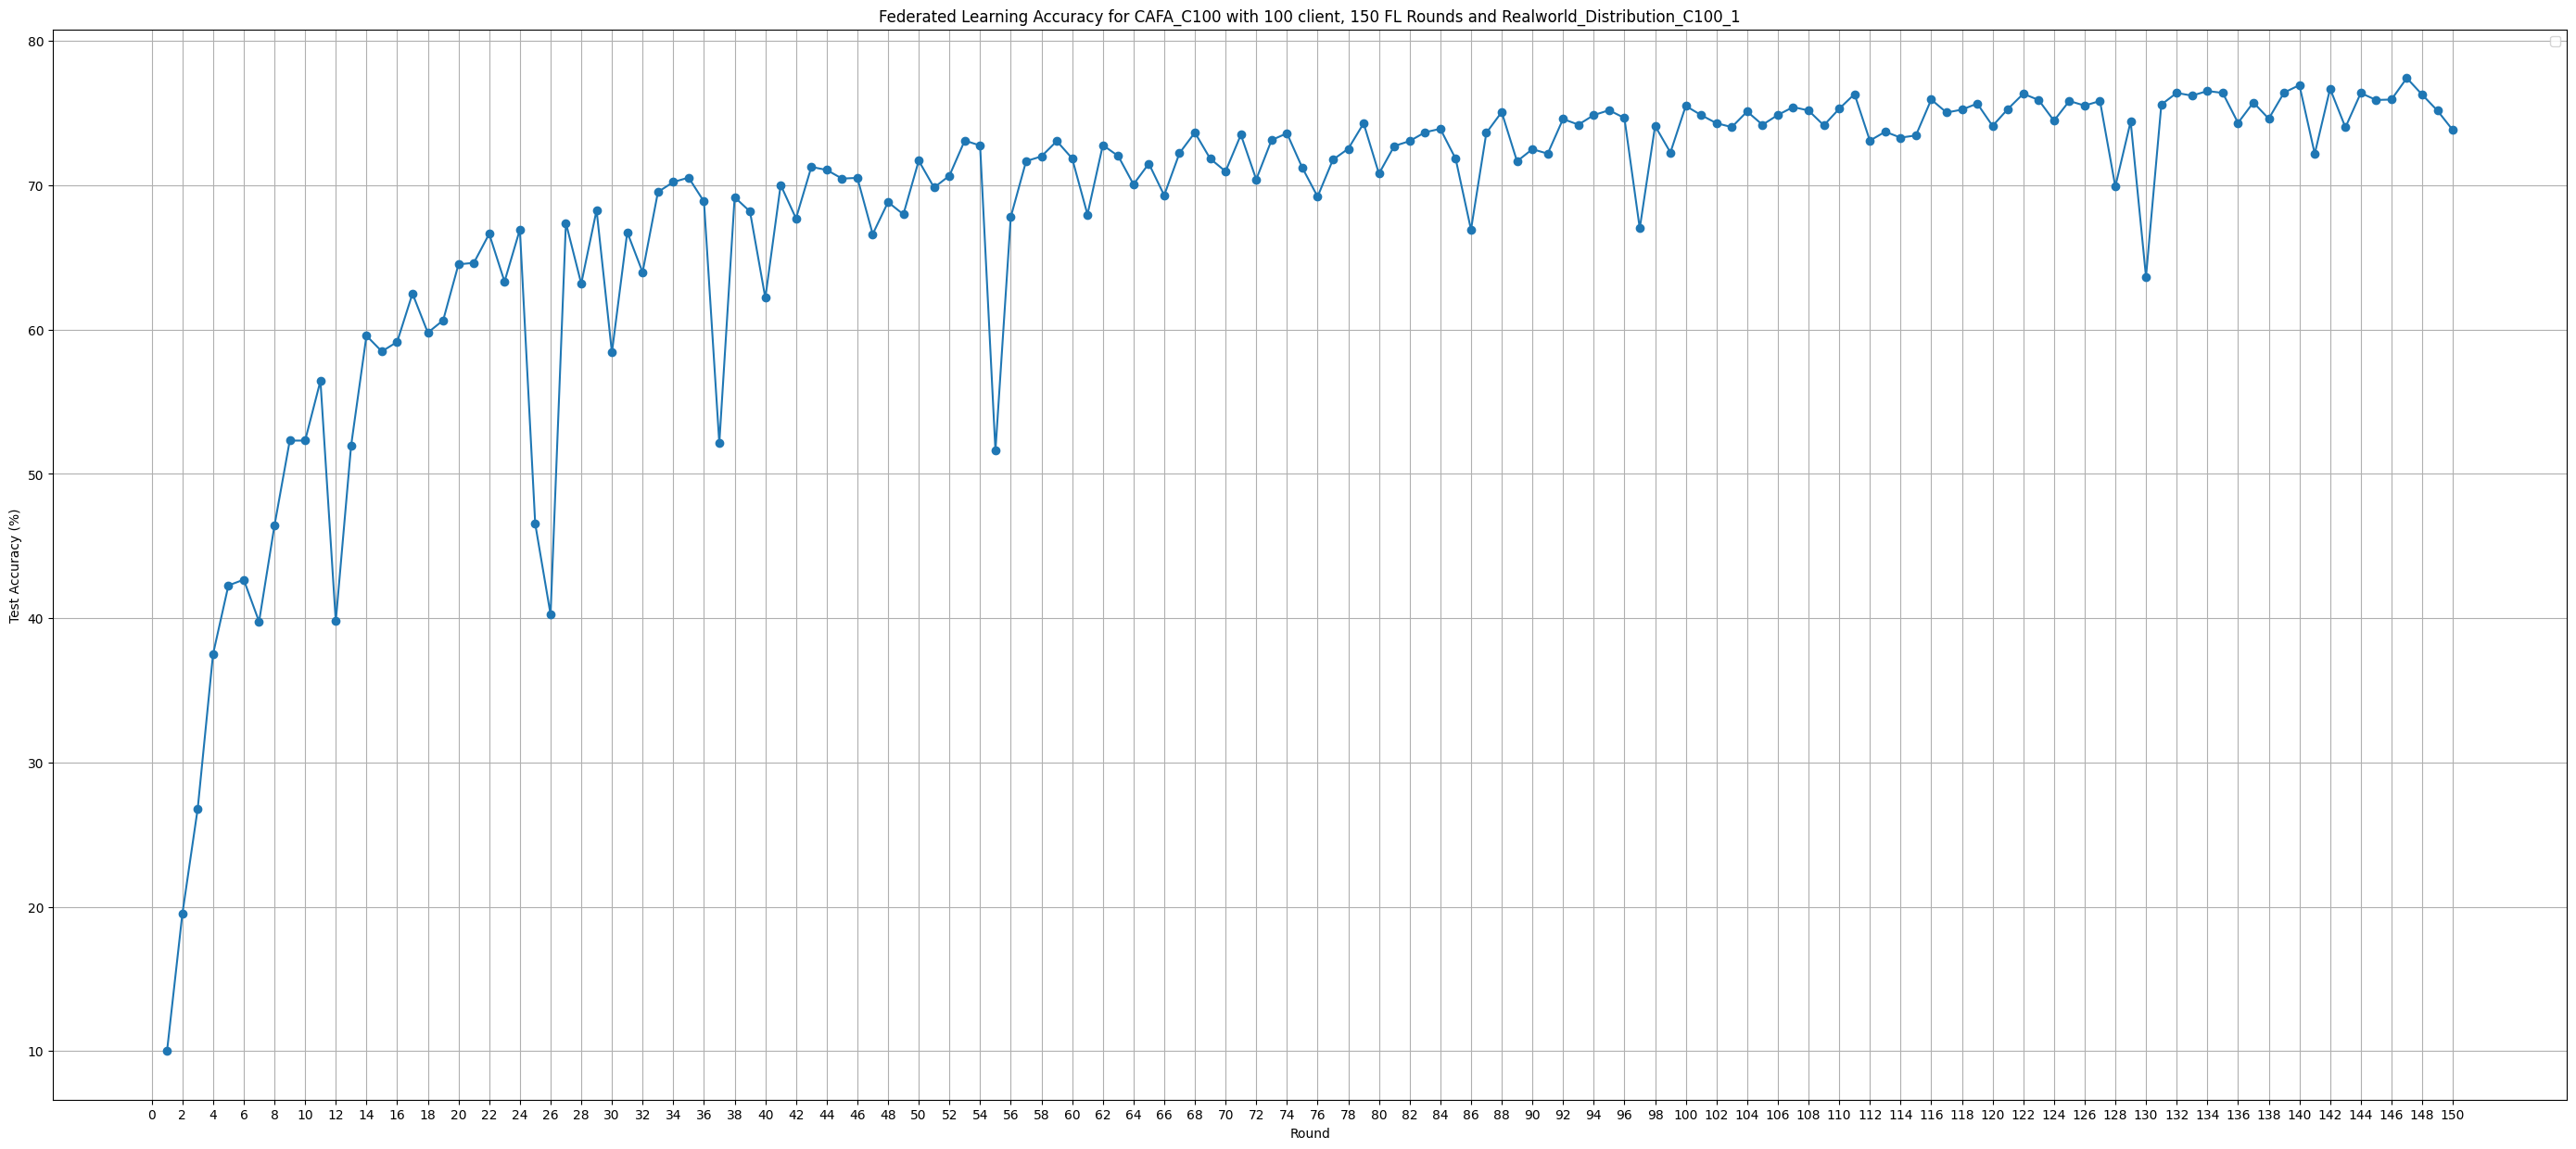

In [38]:
plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), global_accuracy_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Test Accuracy (%)')
plt.title(f'Federated Learning Accuracy for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

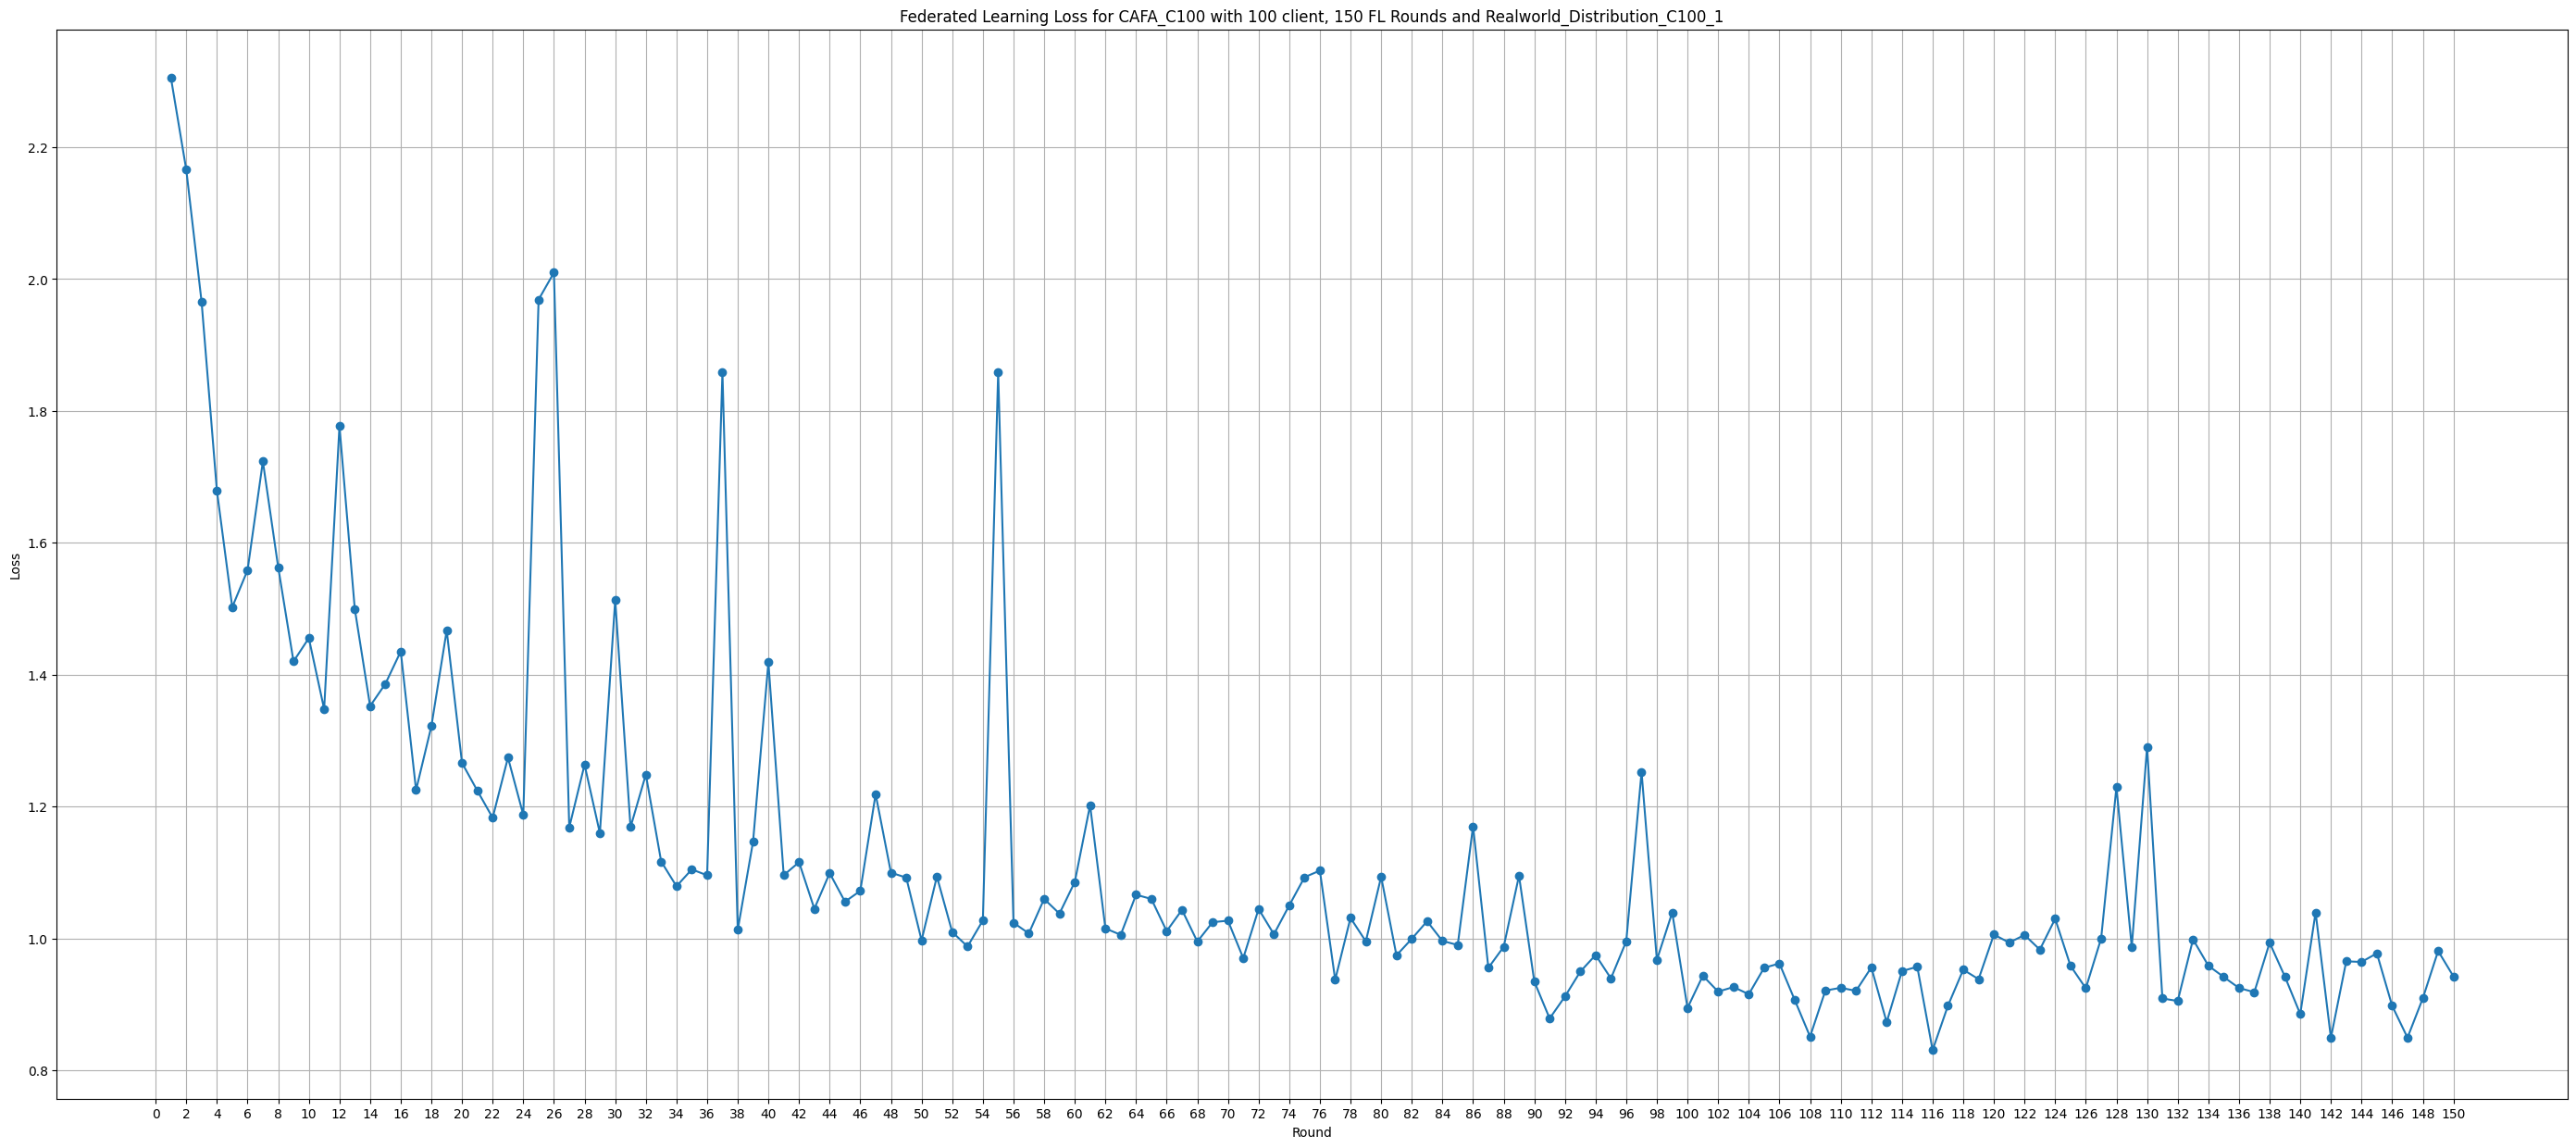

In [39]:
plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), global_loss_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Loss')
plt.title(f'Federated Learning Loss for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.grid(True)
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.show()

/tmp/ipython-input-2396244432.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


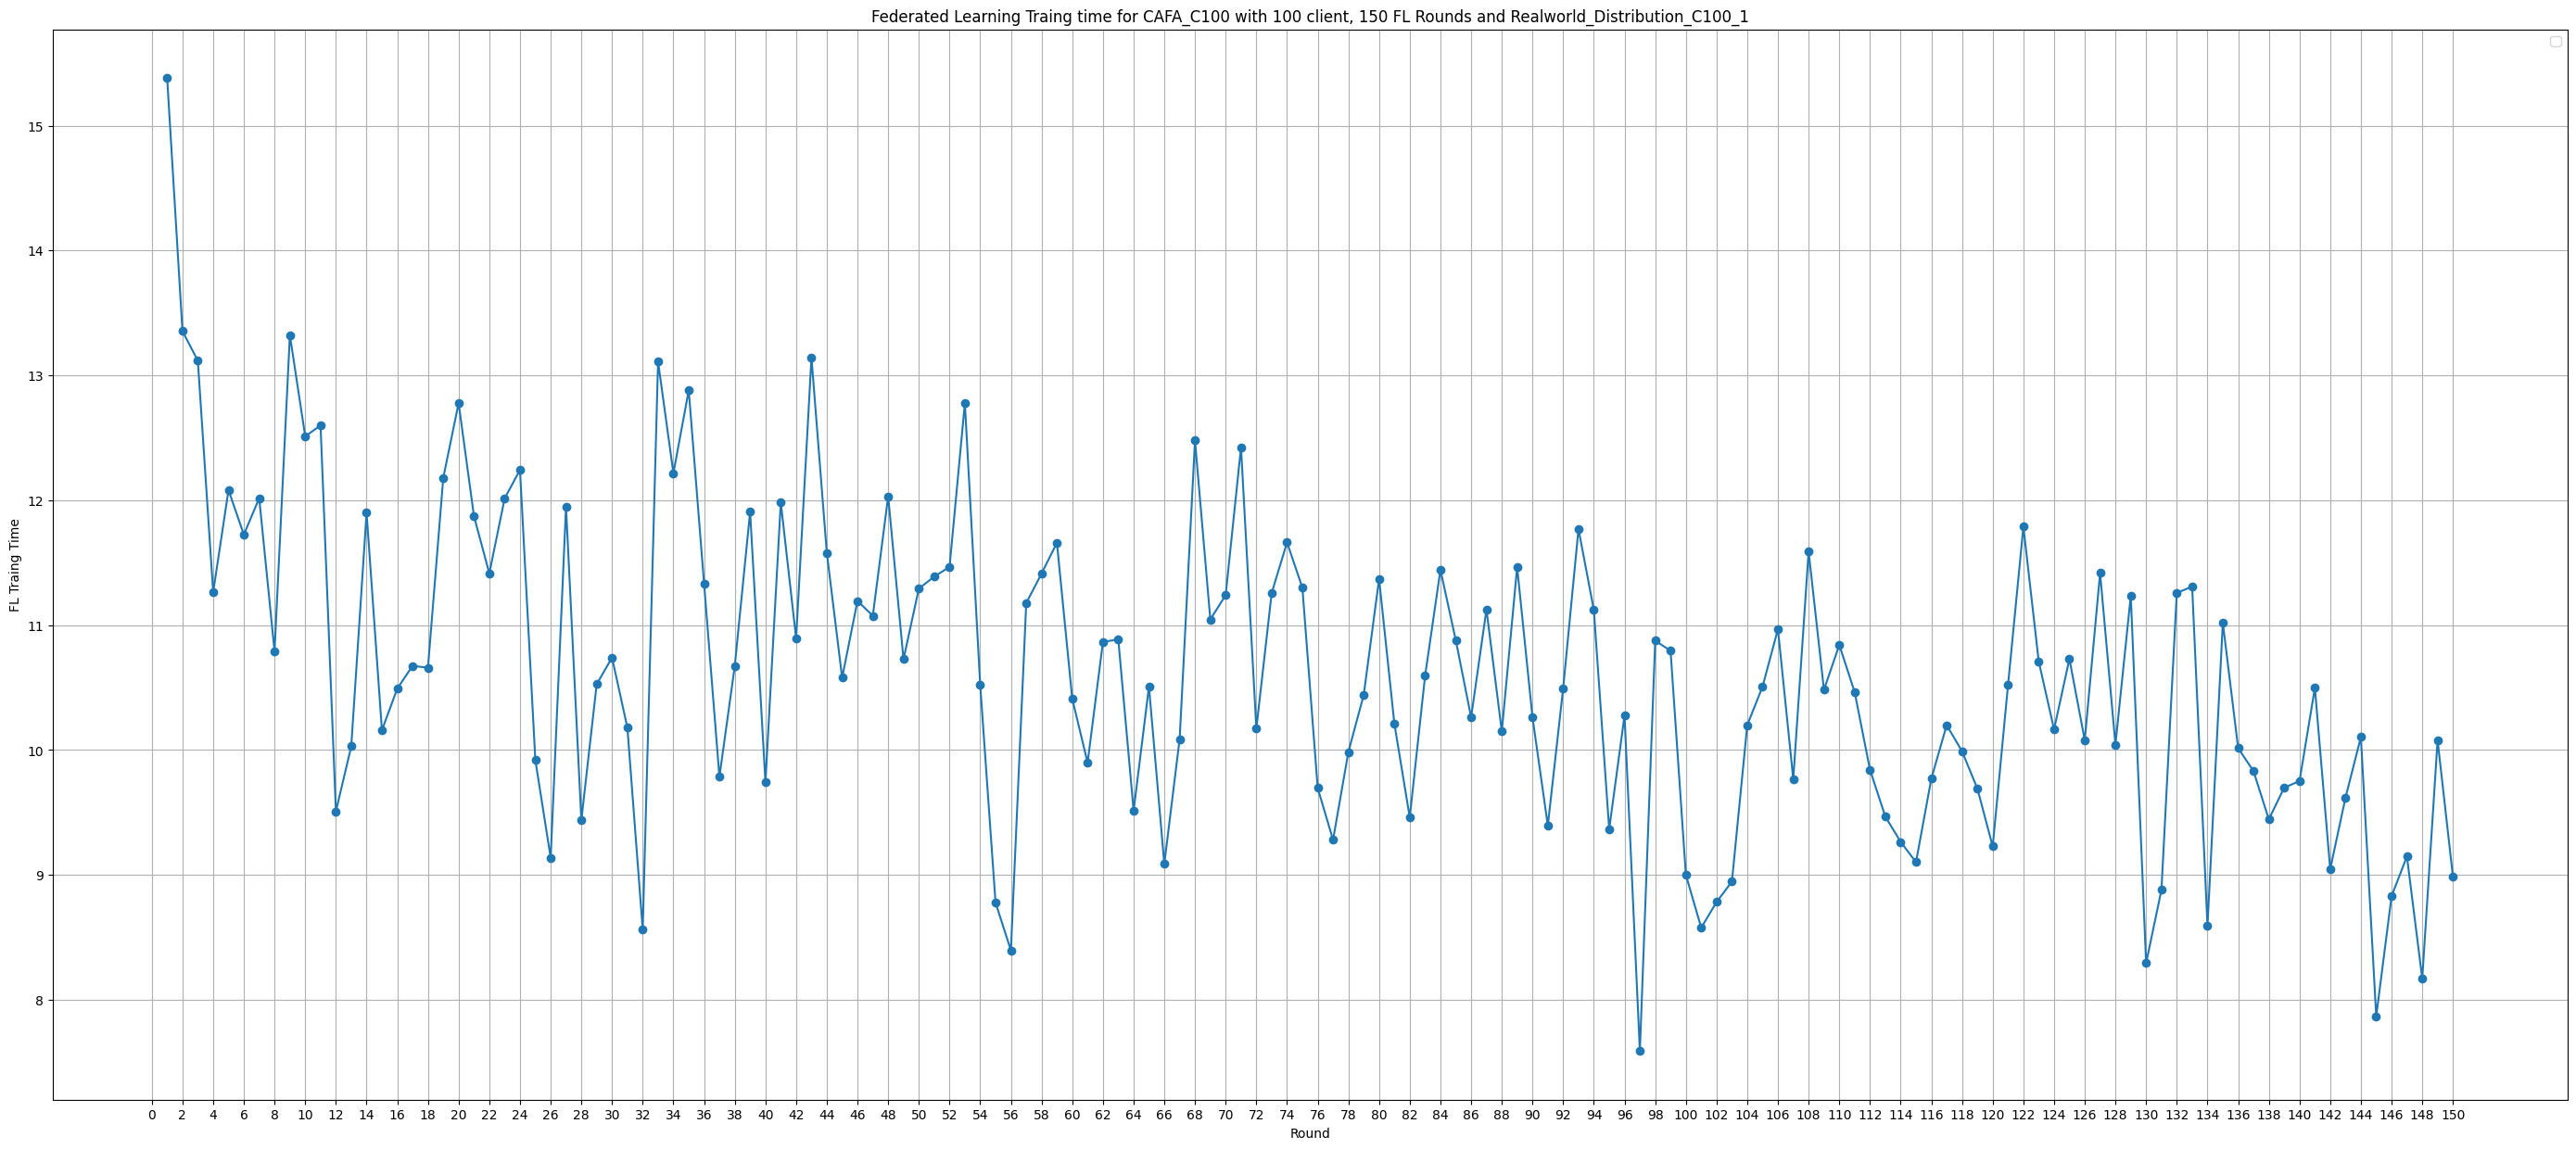

/tmp/ipython-input-2396244432.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


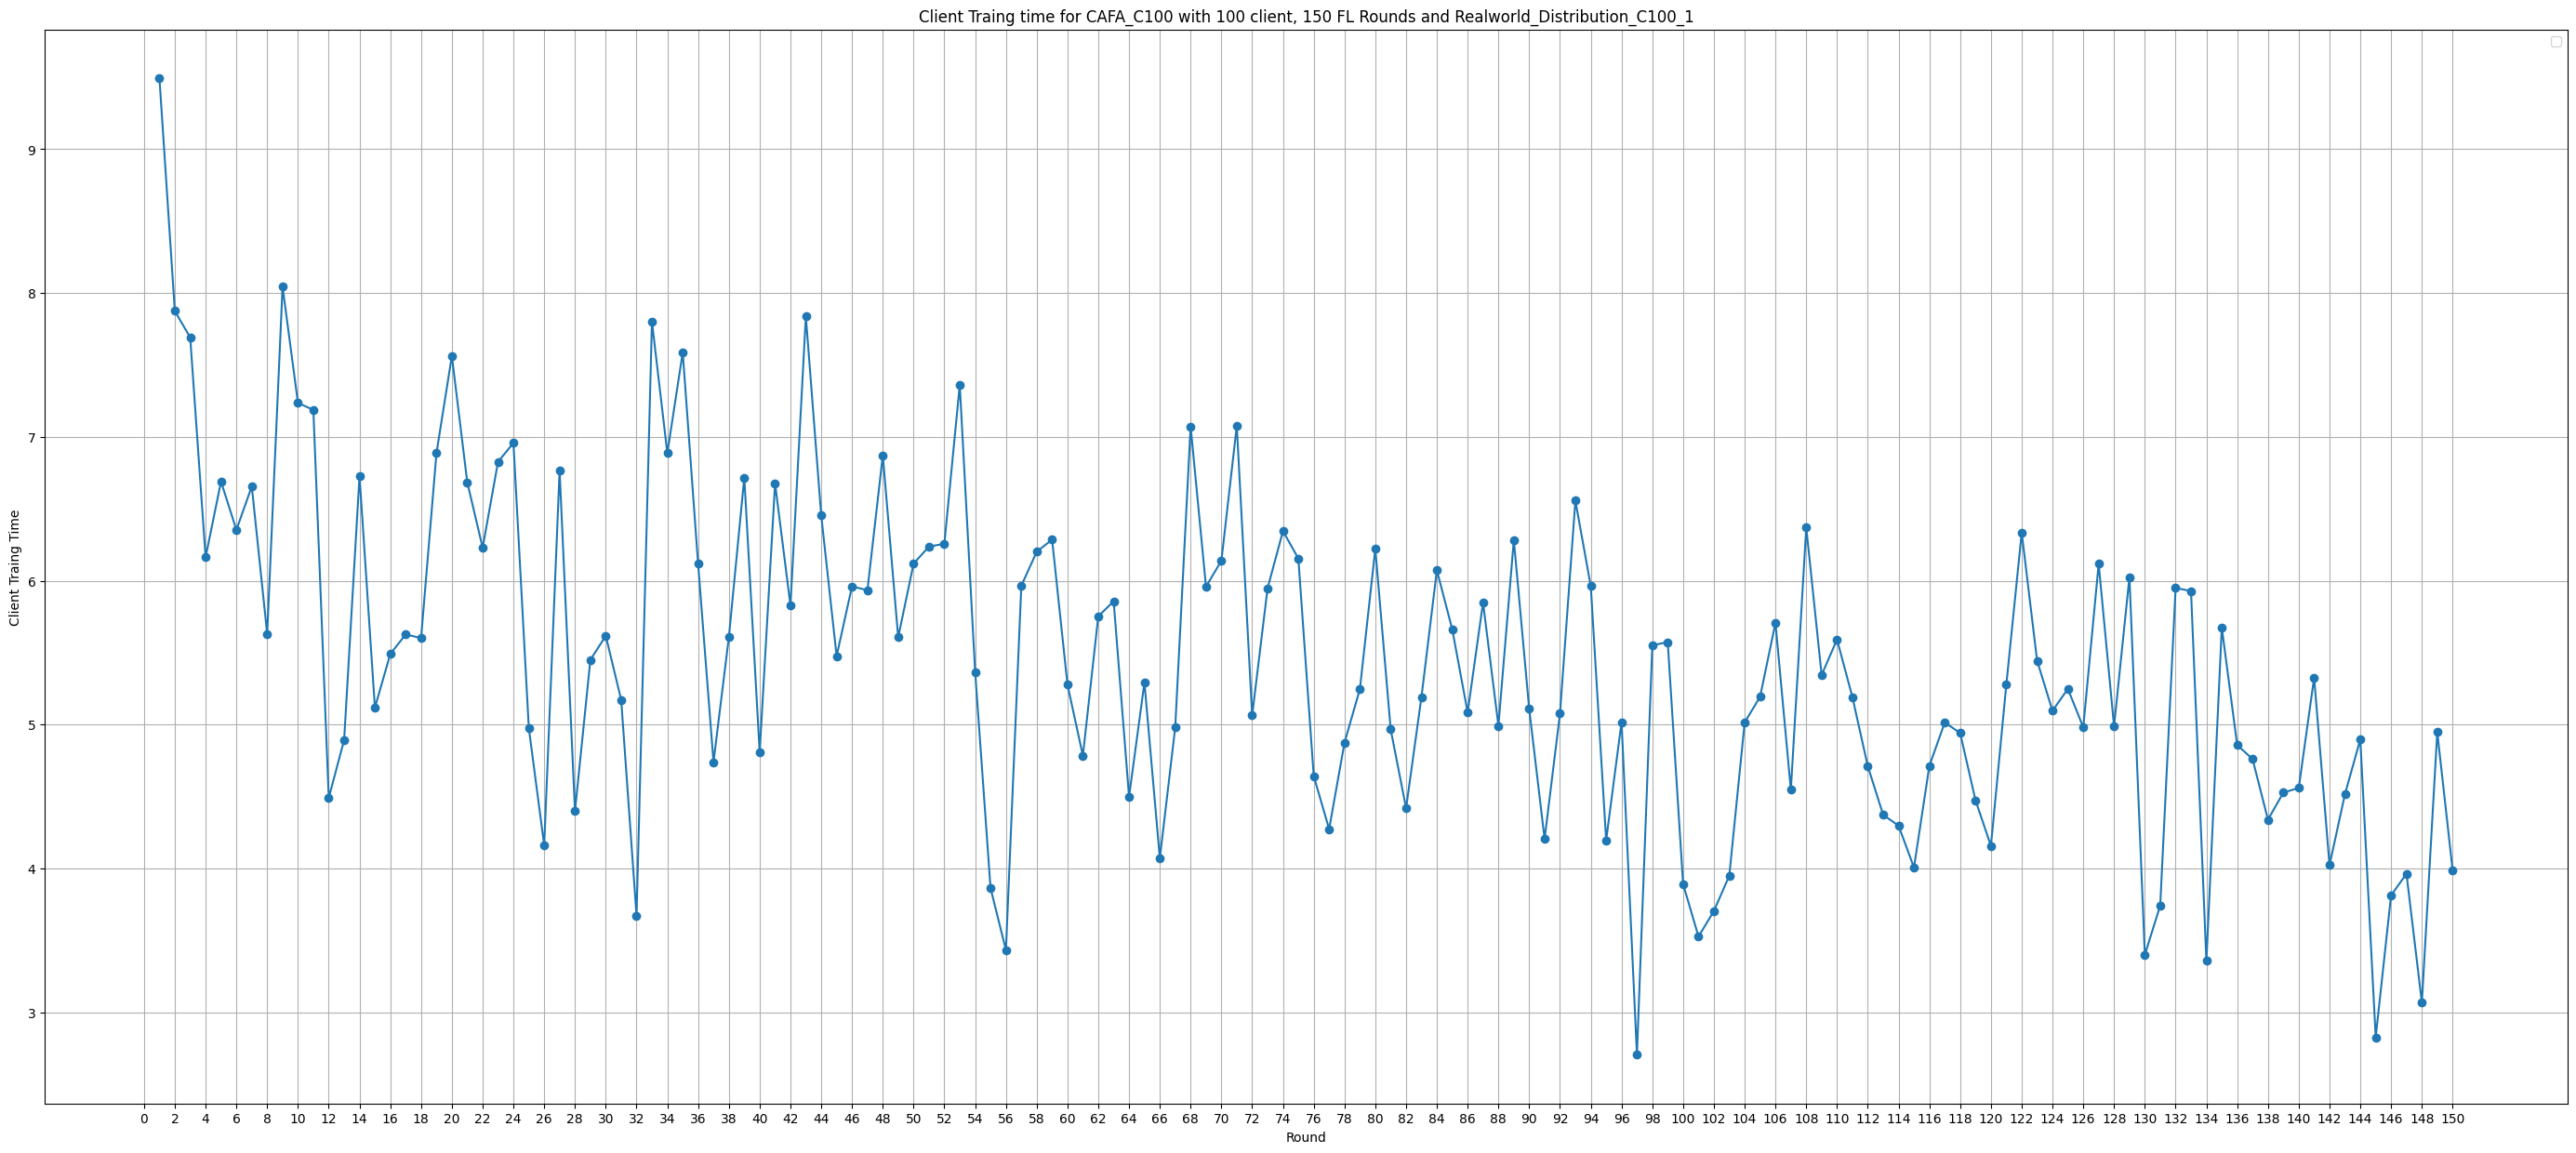

/tmp/ipython-input-2396244432.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


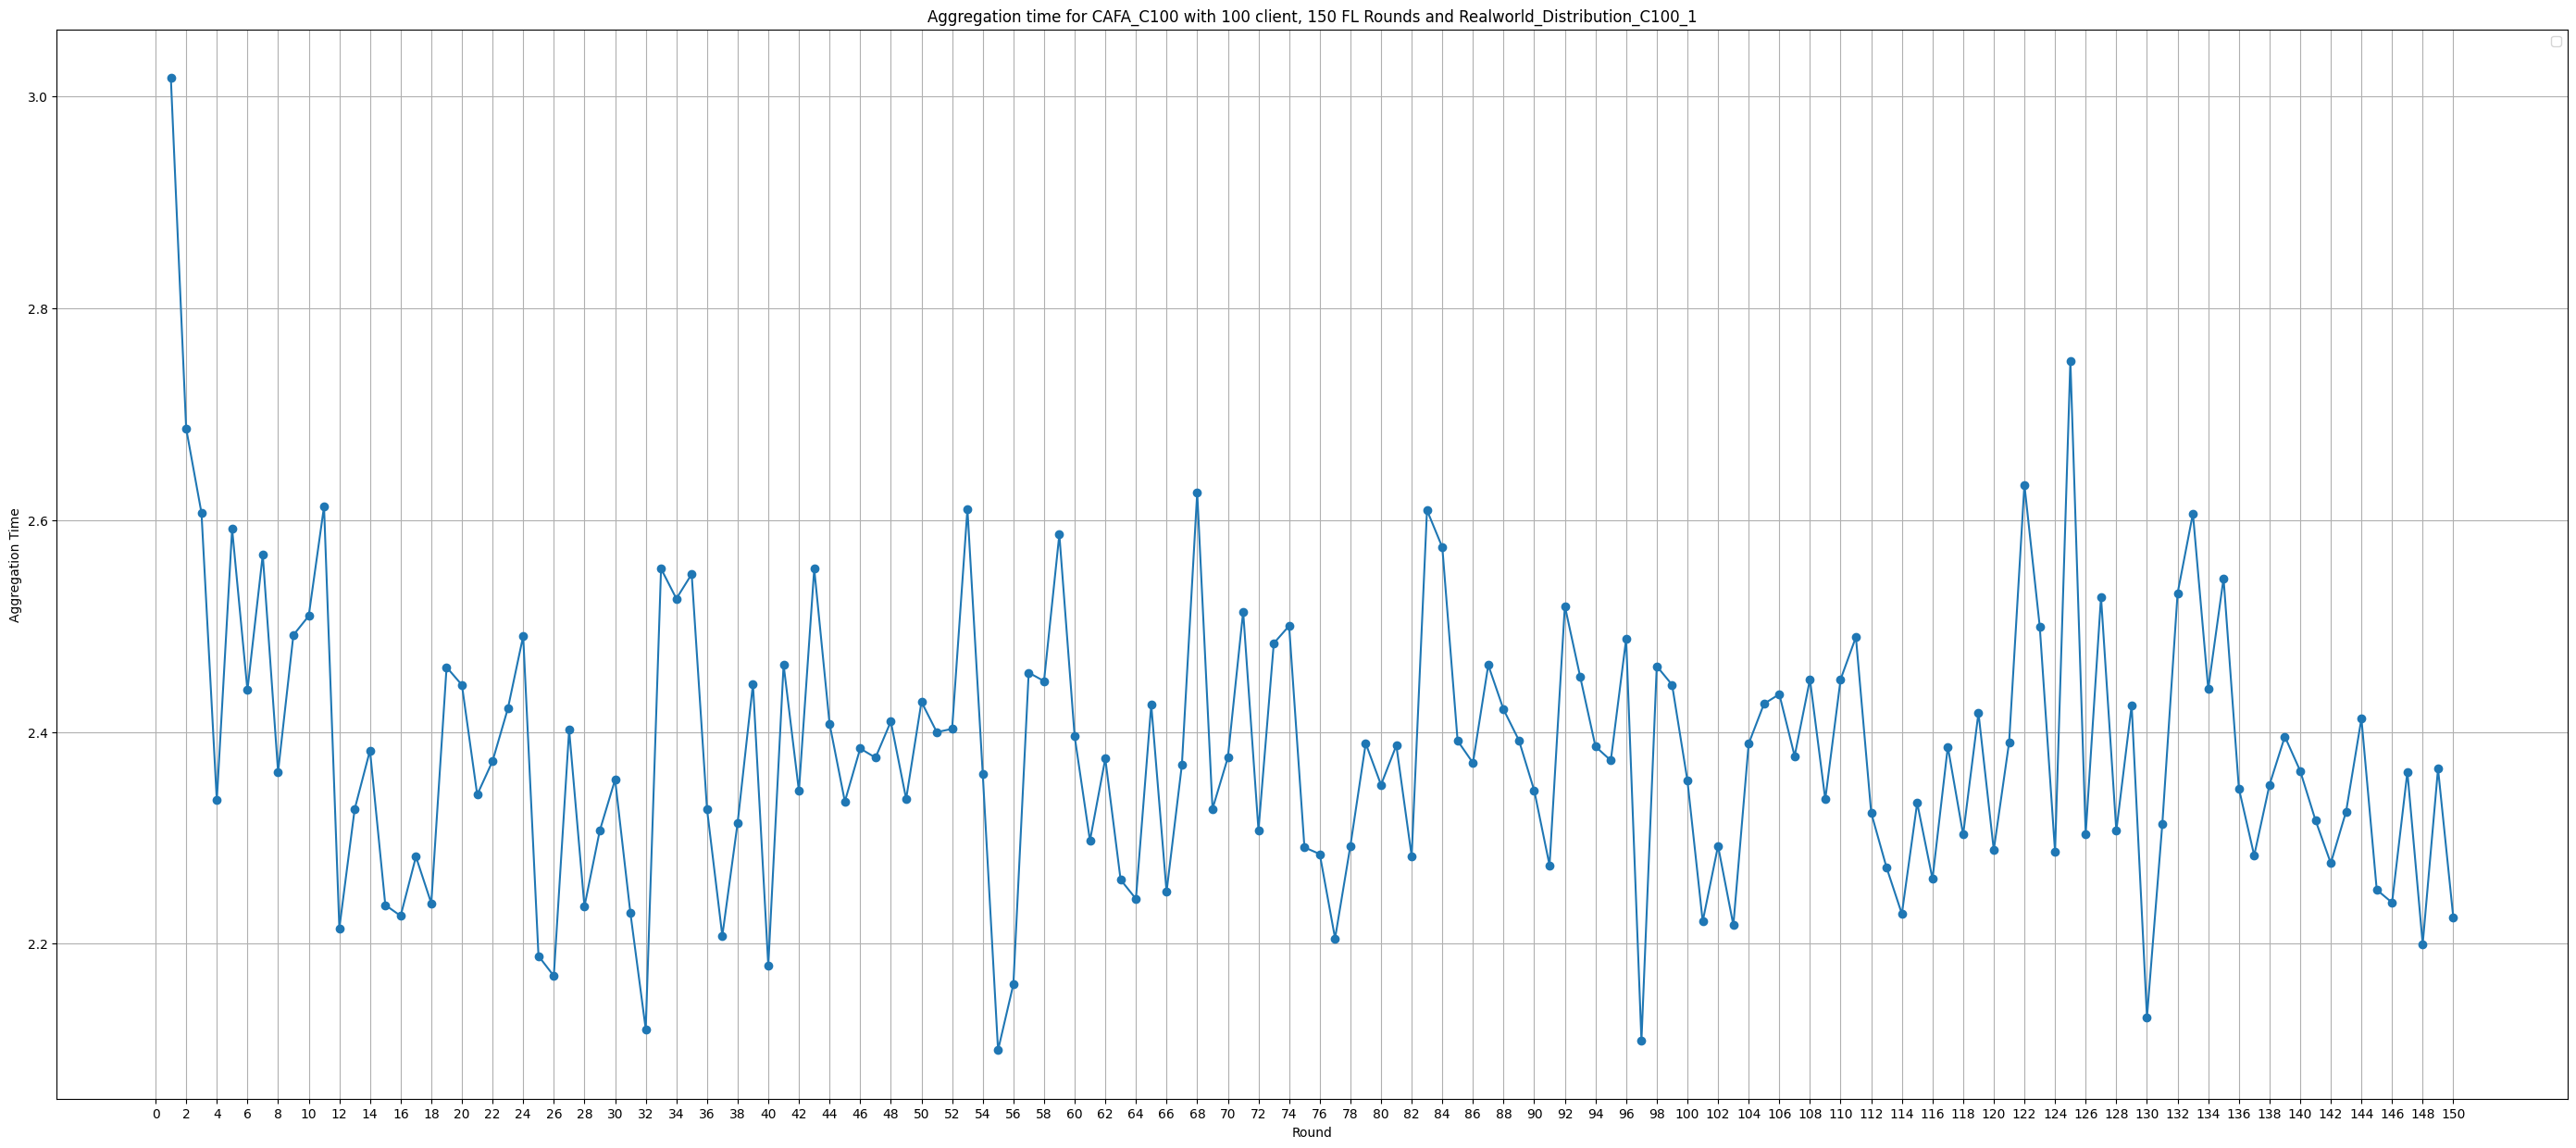

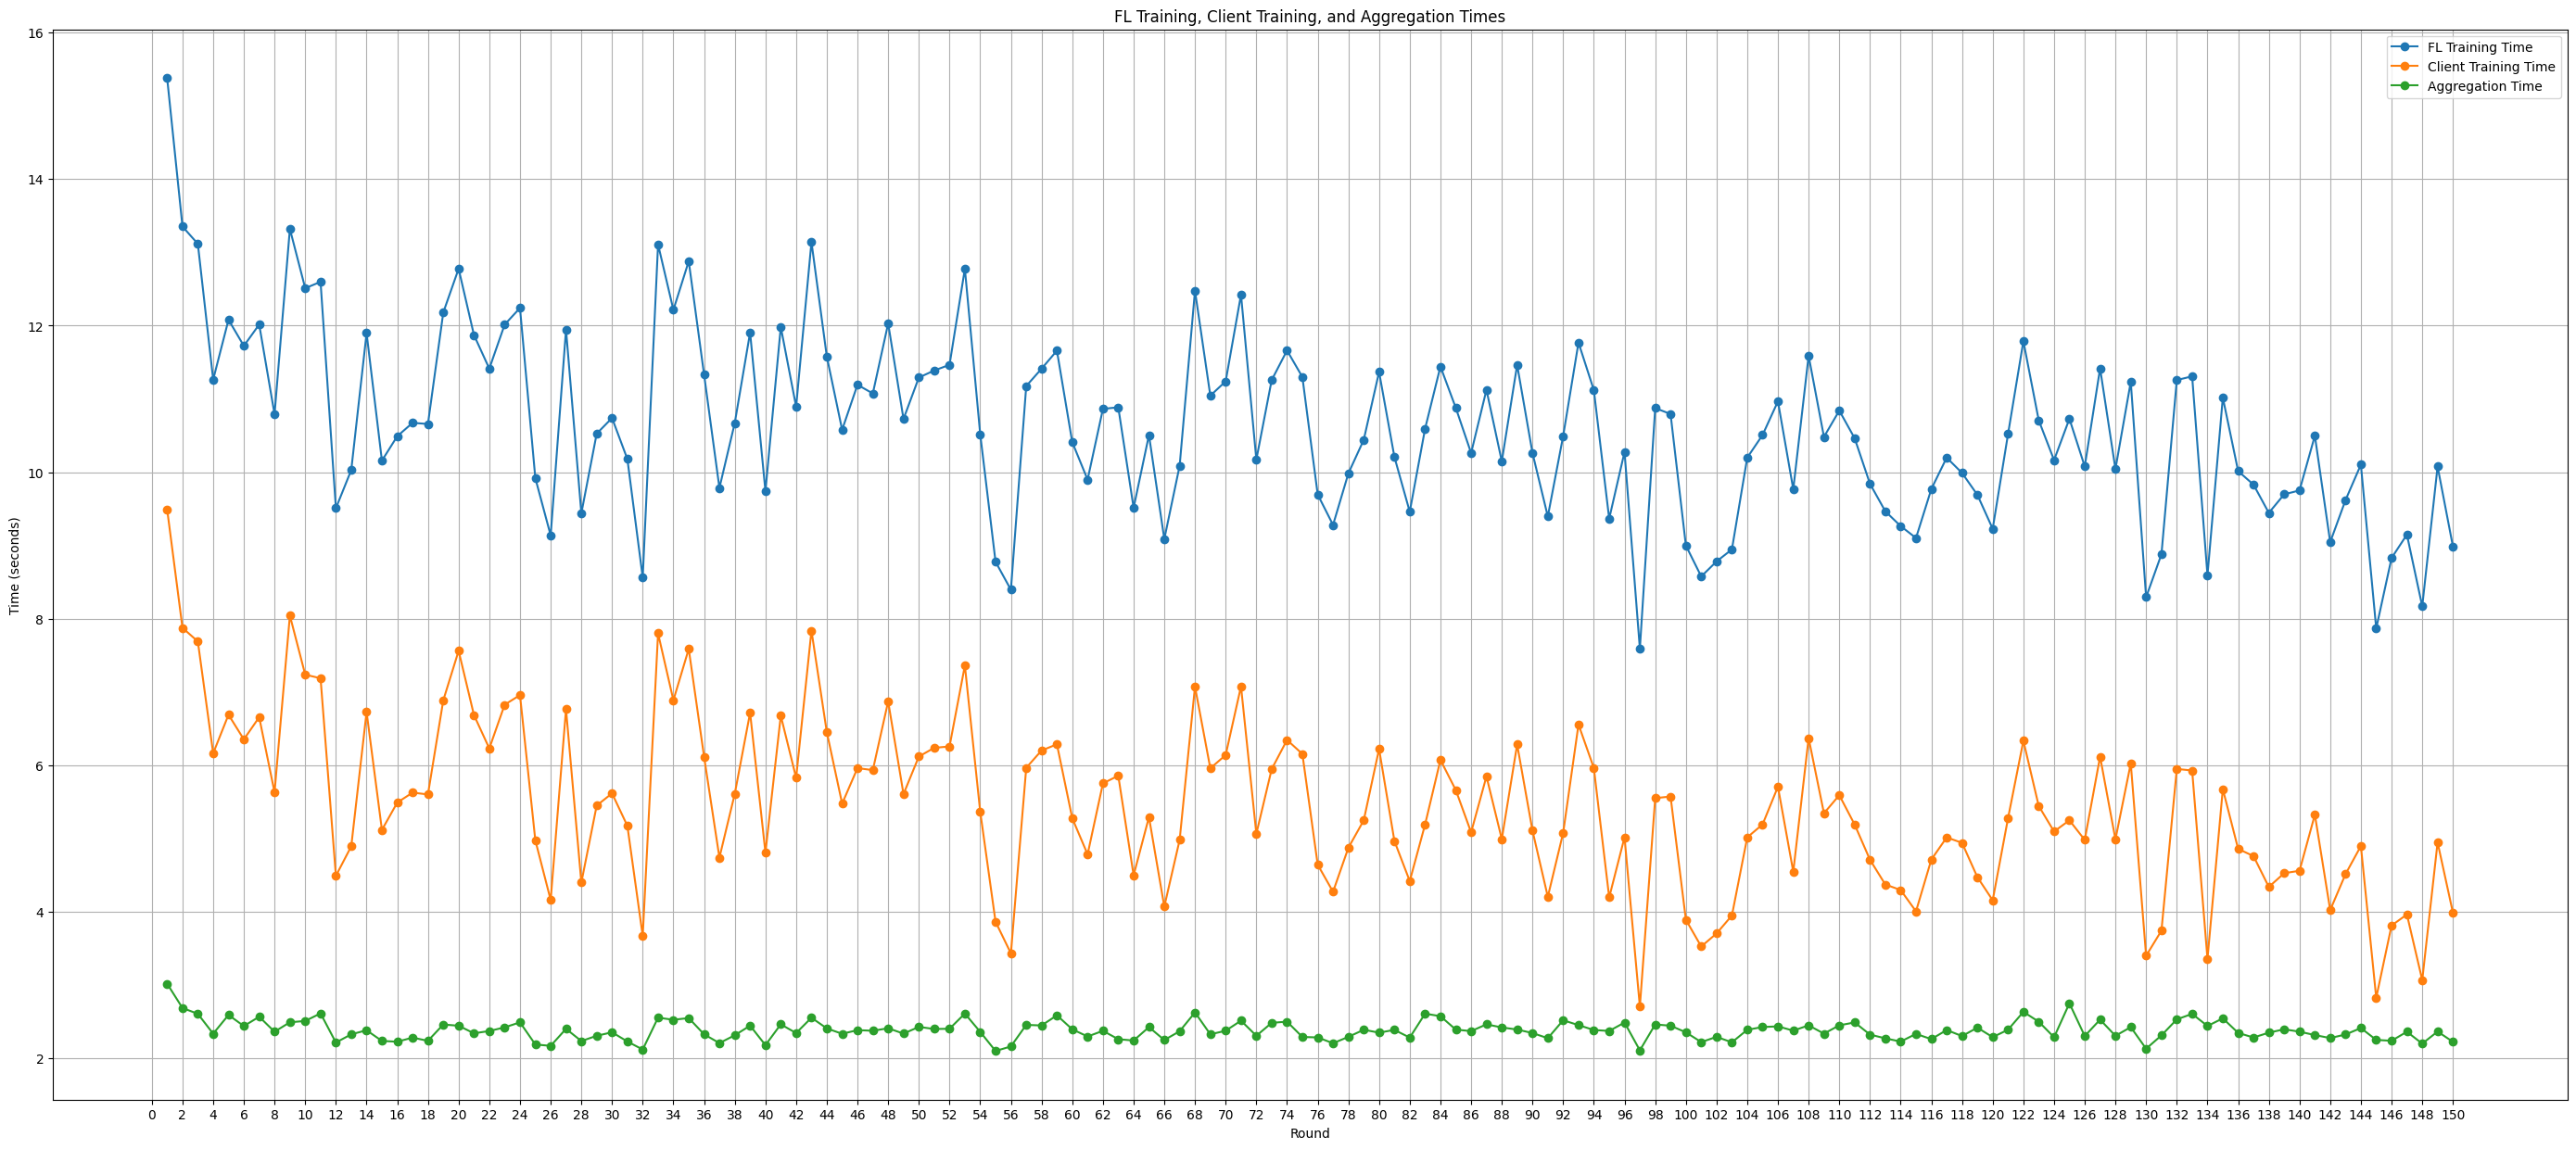

In [40]:
plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), fl_train_time_list, marker='o')
plt.xlabel('Round')
plt.ylabel('FL Traing Time')
plt.title(f'Federated Learning Traing time for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), client_train_time_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Client Traing Time')
plt.title(f'Client Traing time for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), agg_time_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Aggregation Time')
plt.title(f'Aggregation time for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()



plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), fl_train_time_list, marker='o', label='FL Training Time')
plt.plot(range(1, FL_ROUNDS + 1), client_train_time_list, marker='o', label='Client Training Time')
plt.plot(range(1, FL_ROUNDS + 1), agg_time_list, marker='o', label='Aggregation Time')
plt.xlabel('Round')
plt.ylabel('Time (seconds)')
plt.title('FL Training, Client Training, and Aggregation Times')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
wandb.finish()

aggregation_time,▅▅▆▄▄▅▅█▁▄▆▅▄▄▆▄▅▆▆▃▇▆▆▅▄▃▄▃▅▅▄▅▂▅▄▄▇▅▆▄
client_train_time,█▆▇▆▆▅▆▅▆▆▅▃▄▆▆▅▅▃▂▅▄▂▄▂▂▁▂▃▂▁▁▂▂▂▁▂▁▃▂▁
cpu_percent,▁▇▇██▇▆▇▇▆▇▇▇▆▆▇█▇▇▇▇█▆▇▇▇▇▇█▇▇▇▇▇▇▇▆▇▇▆
fl_round_time,▆▅▅▅▅▄█▃▄▅▄▃▄▃▄▅▂▃▄▃▂▄▃▁▂▃▂▂▂▂▂▃▃▃▂▁▂▂▁▁
fl_rounds,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇███
global_accuracy,▂▁▆▇▇▆▇▇▇▇█▇██▇███████████████████████▇█
global_loss,█▂▁▁▁▁▁▁▁▂▁▂▃▁▂▂▂▂▂▁▂▂▂▂▂▂▂▂▂▂▃▃▃▂▂▂▂▂▂▂
gpu_mem_allocated,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gpu_mem_reserved,▁▂██████████████████████████████████████
gpu_percent,▁▅█▅█▁█▁▁▁█▁▅█▁█▁▁█▁██▁▁▁█▁▁▁█▅▁▁█▁█▁██▁
+4,...
